# YSL snRNA-seq Preprocessing & Initial Embedding

#Environment Setup

In [ ]:
# print python version to screen
!python --version

# pip install software
!pip install -q scanpy leidenalg harmonypy
!pip install Scrublet
!pip install -q pydeseq2
!pip install adjustText

#loading libraries and setting the location path for analysis data

import os
import sys
import scipy
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import scipy.io as sio
import scanpy.external as sce
import matplotlib.pyplot as plt
#from anndata import AnnData
import anndata as ad
import scrublet as scr

#Adjust Scanpy default settings

sc.settings.verbosity = 1 # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=100, fontsize=10, dpi_save=300, figsize=(5,4), format='png')

#import helper fnctions from Github
if not os.path.exists('scTools-py'):
  !git clone https://github.com/wagnerde/scTools-py.git
  sys.path.append('scTools-py/')

import scTools_dew as dew

Python 3.12.13
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.0/176.0 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 30.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.6/319.6 kB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 77.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviou

/tmp/ipykernel_2412/189178362.py:29: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=100, fontsize=10, dpi_save=300, figsize=(5,4), format='png')


Cloning into 'scTools-py'...
remote: Enumerating objects: 553, done.
remote: Counting objects: 100% (161/161), done.
remote: Compressing objects: 100% (37/37), done.
remote: Total 553 (delta 140), reused 143 (delta 124), pack-reused 392 (from 1)
Receiving objects: 100% (553/553), 132.29 KiB | 1.45 MiB/s, done.
Resolving deltas: 100% (352/352), done.


In [ ]:
!pip install -q scanpy leidenalg harmonypy

In [ ]:
import scanpy as sc

In [ ]:
import os
import sys
import scipy
import numpy as np
import pandas as pd

import seaborn as sns
import scipy.io as sio
import matplotlib.pyplot as plt


In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


In [ ]:
!pip install "git+https://github.com/WagnerLabUCSF/zmap-tools.git"
import zmap

  Cloning https://github.com/WagnerLabUCSF/zmap-tools.git to /tmp/pip-req-build-tm6fr4fs
  Running command git clone --filter=blob:none --quiet https://github.com/WagnerLabUCSF/zmap-tools.git /tmp/pip-req-build-tm6fr4fs
  Resolved https://github.com/WagnerLabUCSF/zmap-tools.git to commit 4e6e7a3680c66b70226bc181ca2c980911fb2065
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 56.3 MB/s eta 0:00:00
  Created wheel for zmap-tools: filename=zmap_tools-0.2.2.1-py3-none-any.whl size=102028 sha256=9f877157a43cfe028e64ddedff20f2ebcfdc747668bdaff9aa9db09c3b7fc2a1
  Stored in directory: /tmp/pip-ephem-wheel-cache-brn36qon/wheels/fa/51/9a/bda0502ea52767472a4895c2d48391ec3dc4329565d667bbf4
Successfully built zmap-tools


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Data Loading/Preprocessing

##Processing Parse Output into h5ad

Only Run this section once after you get the data. After that, upload the rawdata h5ad.

In [ ]:
save_path = '/content/drive/MyDrive/HS/20240704 6hpf YSL Parse Concat Sequencing/DGE_unfiltered'

In [ ]:
#Reading in data

# The DGE_filtered folder contains the expression matrix, genes, and files
# NOTE: split-pipe versions older than 1.1.0 used 'DGE.mtx'
adata = sc.read_mtx(save_path + '/count_matrix.mtx')

# reading in gene and cell data
gene_data = pd.read_csv(save_path + '/all_genes.csv')
cell_meta = pd.read_csv(save_path + '/cell_metadata.csv')

# find genes with nan values and filter
gene_data = gene_data[gene_data.gene_name.notnull()]
notNa = gene_data.index
notNa = notNa.to_list()

# remove genes with nan values and assign gene names
adata = adata[:,notNa]
adata.var = gene_data
adata.var.set_index('gene_name', inplace=True)
adata.var.index.name = None
adata.var_names_make_unique()

# add cell meta data to anndata object
adata.obs = cell_meta
adata.obs.set_index('bc_wells', inplace=True)
adata.obs.index.name = None
adata.obs_names_make_unique()

sc.pp.filter_cells(adata, min_genes=300)
sc.pp.filter_genes(adata, min_cells=5)

# Returns the dimensions of the expression matrix (cells, genes)
adata.shape

/usr/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


(63864, 31859)

In [ ]:
#Ensure dataframe looks correct
adata.obs

,sample,species,gene_count,tscp_count,mread_count,bc1_well,bc2_well,bc3_well,bc1_wind,bc2_wind,bc3_wind,n_genes
01_01_01__s1,6hpf_YSL_4_24_1,danRer11,495,661,1976,A1,A1,A1,1,1,1,495
01_01_09__s1,6hpf_YSL_4_24_1,danRer11,2200,4257,12661,A1,A1,A9,1,1,9,2200
01_01_10__s1,6hpf_YSL_4_24_1,danRer11,881,1502,4192,A1,A1,A10,1,1,10,881
01_01_13__s1,6hpf_YSL_4_24_1,danRer11,424,1049,3150,A1,A1,B1,1,1,13,424
01_01_25__s1,6hpf_YSL_4_24_1,danRer11,3078,8753,25984,A1,A1,C1,1,1,25,3078
...,...,...,...,...,...,...,...,...,...,...,...,...
12_96_83__s2,6hpf_cells_1_3,danRer11,462,731,1534,A12,H12,G11,12,96,83,462
12_96_86__s2,6hpf_cells_1_3,danRer11,320,491,1078,A12,H12,H2,12,96,86,320
12_96_90__s2,6hpf_cells_1_3,danRer11,5810,36448,111741,A12,H12,H6,12,96,90,5810
12_96_92__s2,6hpf_cells_1_3,danRer11,321,487,1020,A12,H12,H8,12,96,92,321


##Counts Filtering (use with DGE_unfiltered)

In [ ]:
adata.raw = adata.copy()

In [ ]:
adata.obs['sample'].unique()

['6hpf_YSL_4_24_1', '6hpf_YSL_4_24_2', '6hpf_YSL_4_30_1', '6hpf_YSL_4_30_2', '6hpf_YSL_5_01_1', ..., '6hpf_YSL_5_02_2', '6hpf_YSL_5_07_1', '6hpf_cells_1_1', '6hpf_cells_1_2', '6hpf_cells_1_3']
Length: 12
Categories (12, object): ['6hpf_YSL_4_24_1', '6hpf_YSL_4_24_2', '6hpf_YSL_4_30_1', '6hpf_YSL_4_30_2',
                          ..., '6hpf_YSL_5_07_1', '6hpf_cells_1_1', '6hpf_cells_1_2',
                          '6hpf_cells_1_3']

In [ ]:
#Defining Samples here for future use if needed
#samples = ['6hpf_YSL_4_24_1', '6hpf_YSL_4_24_2', '6hpf_YSL_4_30_1', '6hpf_YSL_4_30_2',
           #'6hpf_YSL_5_01_1', '6hpf_YSL_5_01_2', '6hpf_YSL_5_02_1', '6hpf_YSL_5_02_2',
           #'6hpf_YSL_5_07_1', '6hpf_cells_1_1', '6hpf_cells_1_2', '6hpf_cells_1_3']

In [ ]:
samples = adata.obs['sample'].unique()

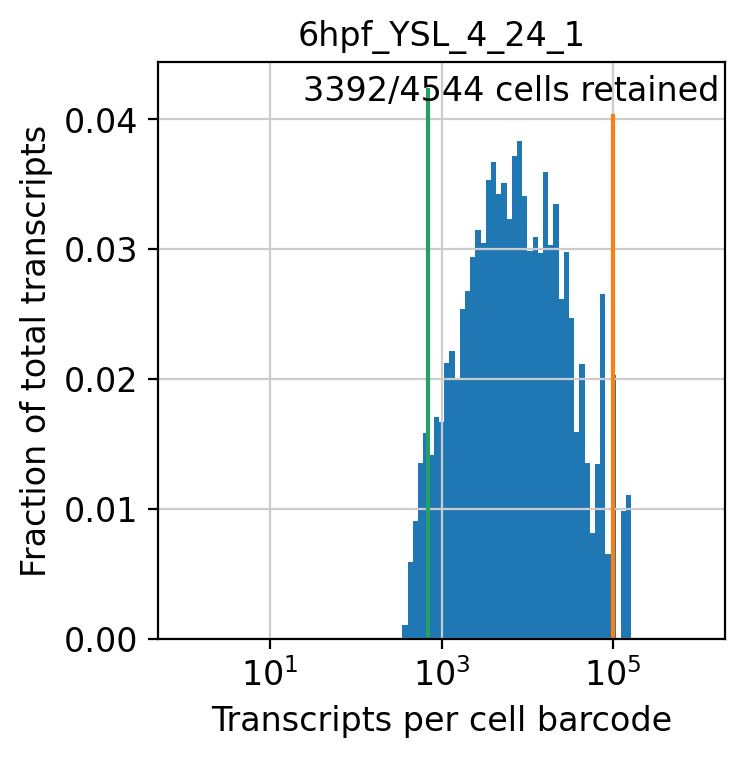

Barcode Filtering 6hpf_YSL_4_24_1 (3392/4544 cells retained)



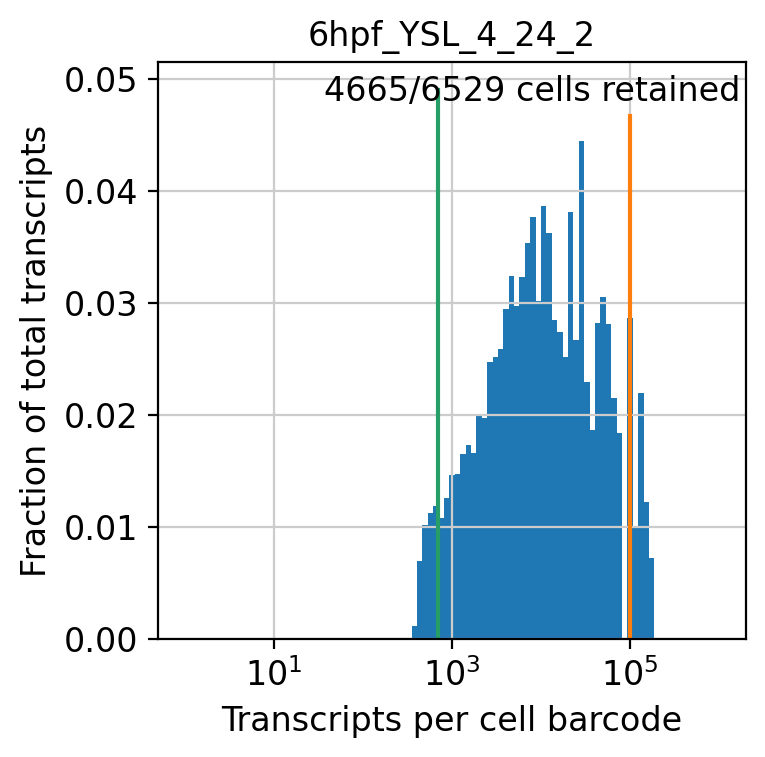

Barcode Filtering 6hpf_YSL_4_24_2 (4665/6529 cells retained)



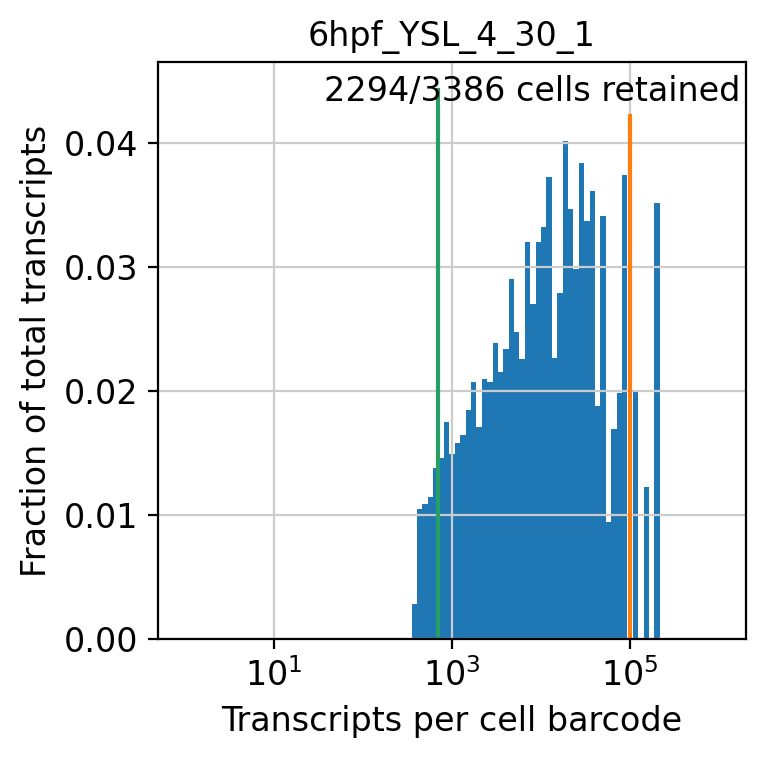

Barcode Filtering 6hpf_YSL_4_30_1 (2294/3386 cells retained)



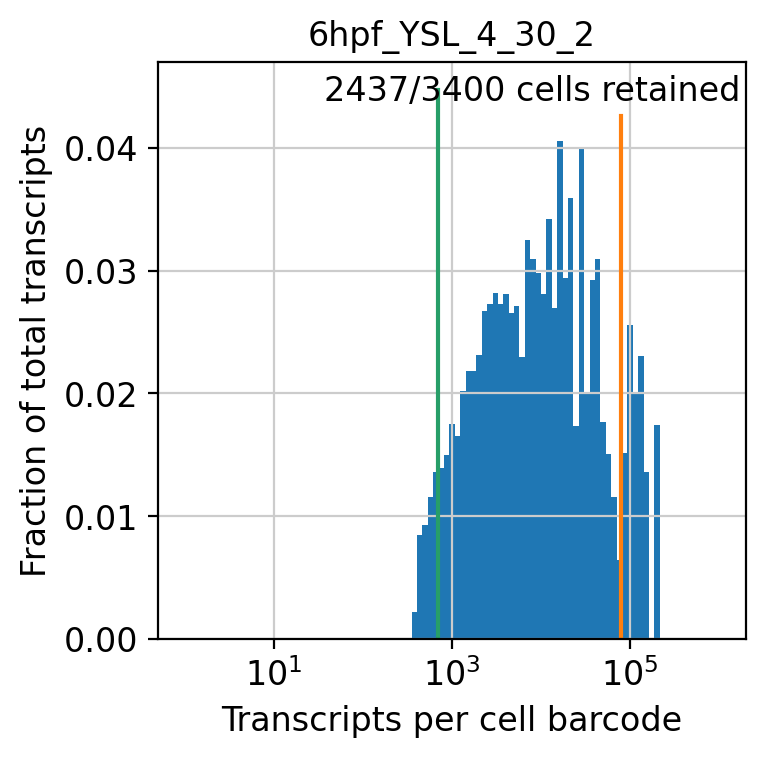

Barcode Filtering 6hpf_YSL_4_30_2 (2437/3400 cells retained)



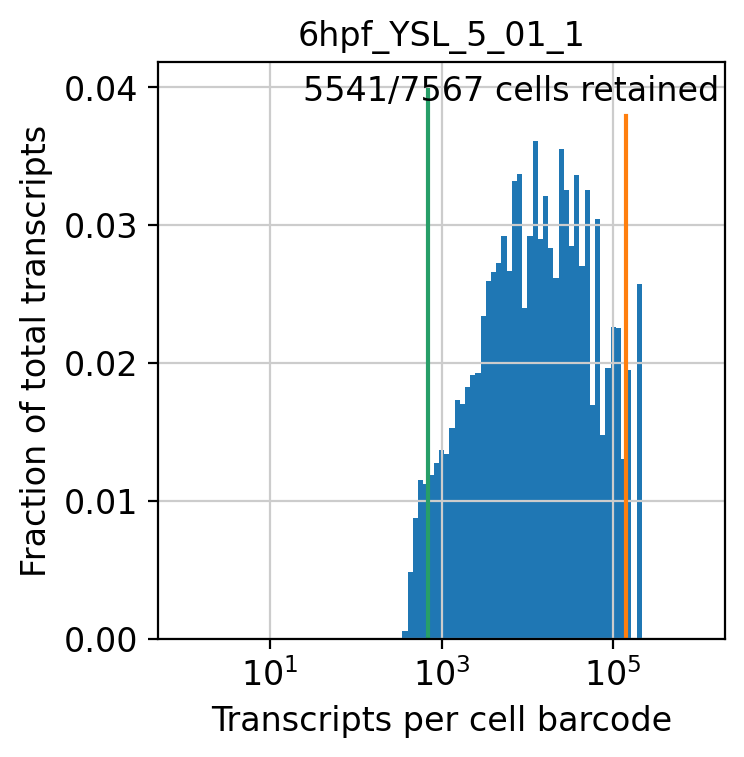

Barcode Filtering 6hpf_YSL_5_01_1 (5541/7567 cells retained)



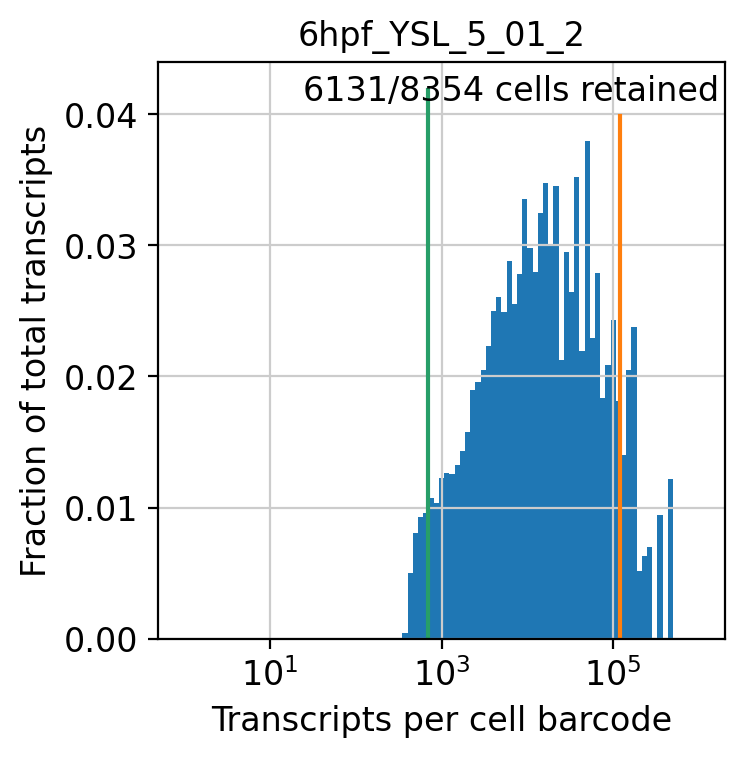

Barcode Filtering 6hpf_YSL_5_01_2 (6131/8354 cells retained)



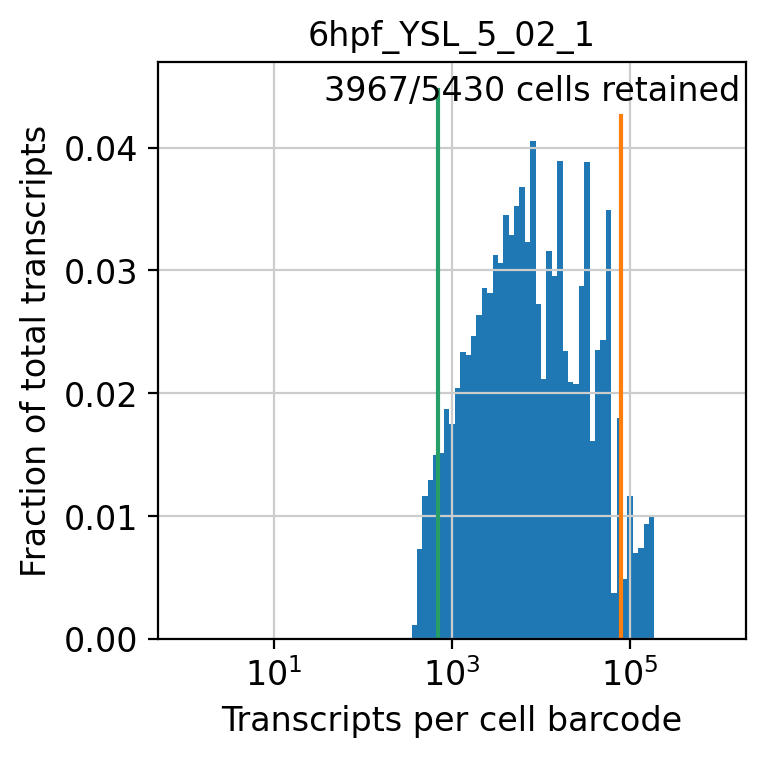

Barcode Filtering 6hpf_YSL_5_02_1 (3967/5430 cells retained)



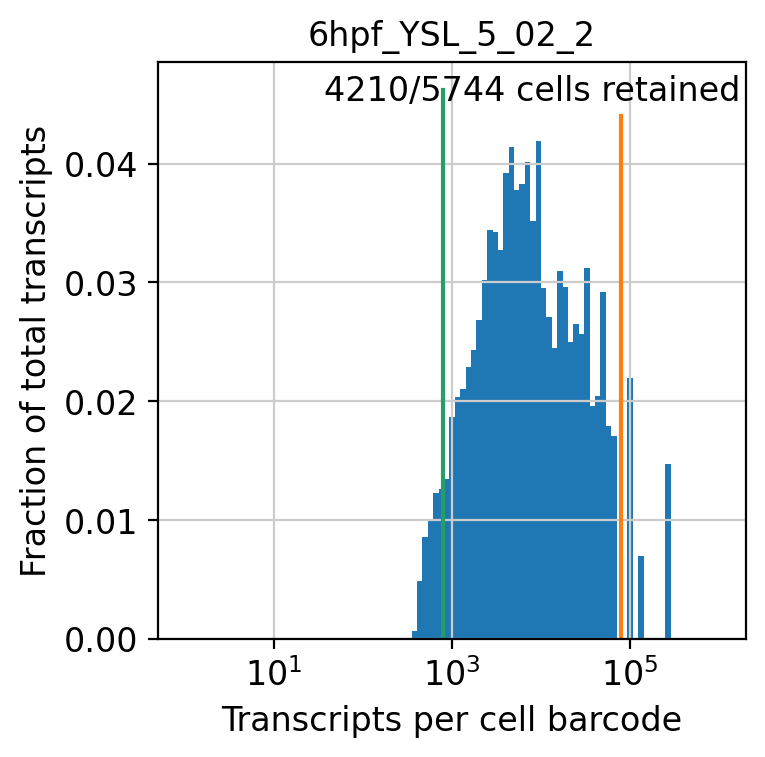

Barcode Filtering 6hpf_YSL_5_02_2 (4210/5744 cells retained)



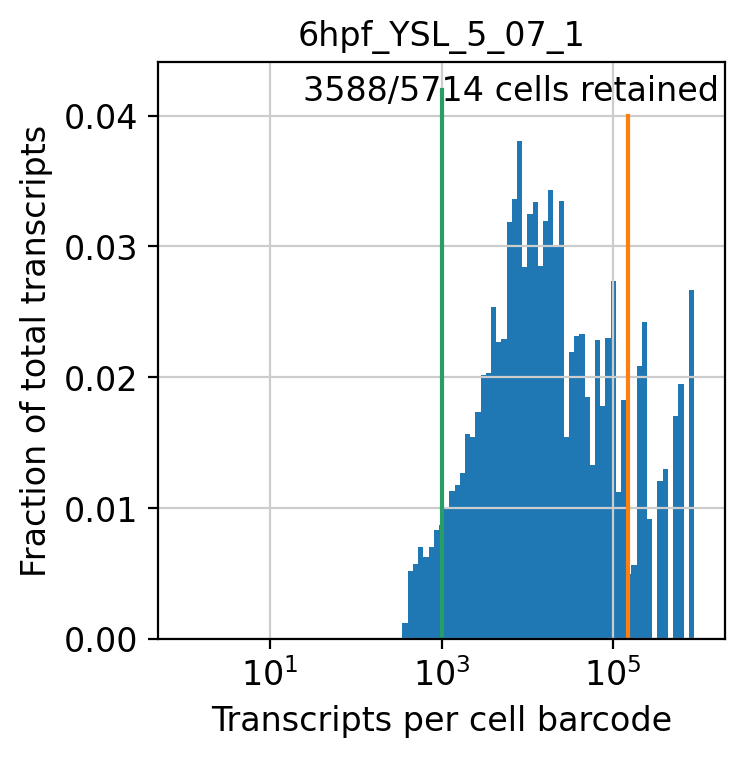

Barcode Filtering 6hpf_YSL_5_07_1 (3588/5714 cells retained)



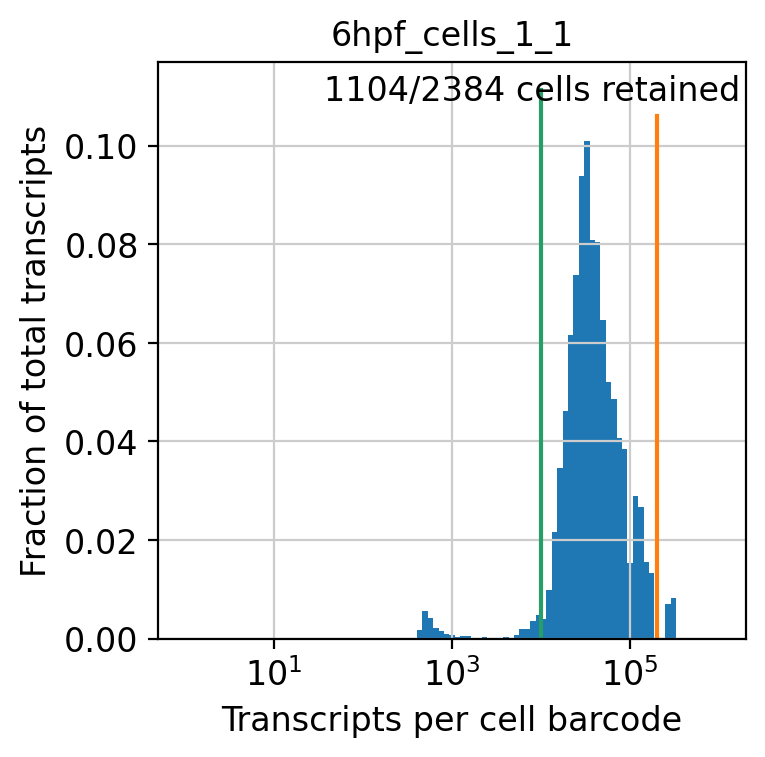

Barcode Filtering 6hpf_cells_1_1 (1104/2384 cells retained)



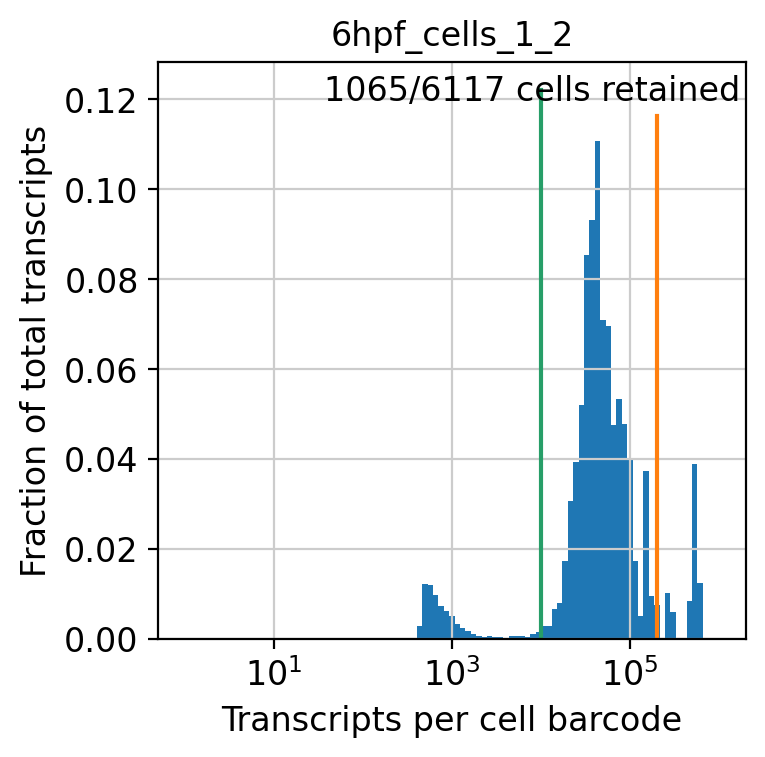

Barcode Filtering 6hpf_cells_1_2 (1065/6117 cells retained)



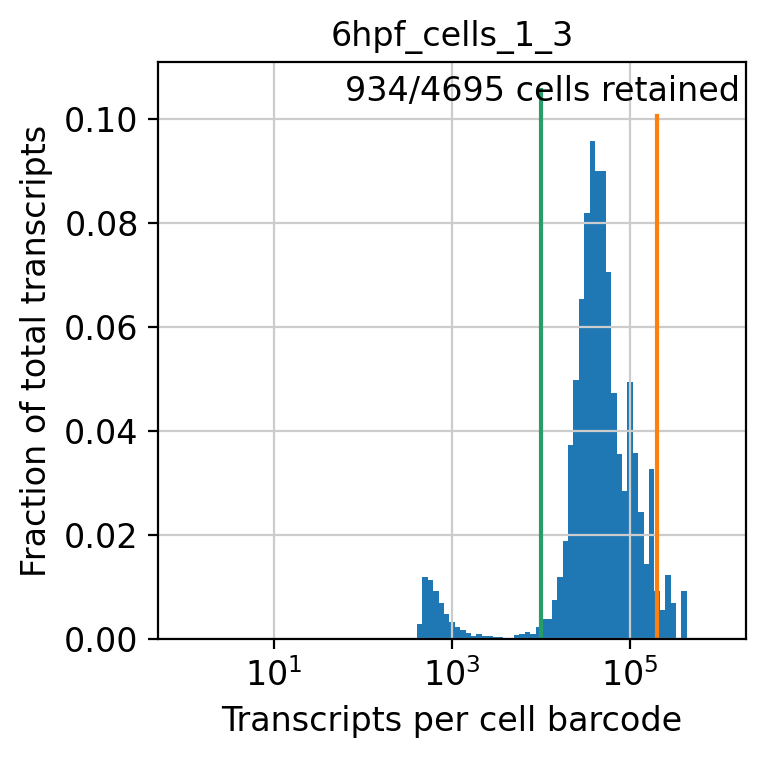

Barcode Filtering 6hpf_cells_1_3 (934/4695 cells retained)



In [ ]:
# Define thresholds for each sample
sample_thresholds = {
    '6hpf_YSL_4_24_1': {'lower': 700, 'upper': 100000},
    '6hpf_YSL_4_24_2': {'lower': 700, 'upper': 100000},
    '6hpf_YSL_4_30_1': {'lower': 700, 'upper': 100000},
    '6hpf_YSL_4_30_2': {'lower': 700, 'upper': 80000},
    '6hpf_YSL_5_01_1': {'lower': 700, 'upper': 140000},
    '6hpf_YSL_5_01_2': {'lower': 700, 'upper': 120000},
    '6hpf_YSL_5_02_1': {'lower': 700, 'upper': 80000},
    '6hpf_YSL_5_02_2': {'lower': 800, 'upper': 80000},
    '6hpf_YSL_5_07_1': {'lower': 1000, 'upper': 150000},
    '6hpf_cells_1_1': {'lower': 10000, 'upper': 200000},
    '6hpf_cells_1_2': {'lower': 10000, 'upper': 200000},
    '6hpf_cells_1_3': {'lower': 10000, 'upper': 200000},
}

# Get unique sample IDs from the 'sample' column
samples = adata.obs['sample'].unique()

# Filter each sample separately with custom thresholds
for sample in samples:
    # Subset data for this sample
    adata_sample = adata[adata.obs['sample'] == sample].copy()

    # Get thresholds for this sample
    thresholds = sample_thresholds[sample]

    # Apply filtering with sample-specific thresholds
    zmap.pp.filter_abundant_barcodes(
        adata_sample,
        filter_cells=False,
        library_id=sample,
        threshold=thresholds['lower'],
        upper_threshold=thresholds['upper']
    )

In [ ]:
#To save the thresholds to each sample

# Define thresholds for each sample
sample_thresholds = {
    '6hpf_YSL_4_24_1': {'lower': 700, 'upper': 100000},
    '6hpf_YSL_4_24_2': {'lower': 700, 'upper': 100000},
    '6hpf_YSL_4_30_1': {'lower': 700, 'upper': 100000},
    '6hpf_YSL_4_30_2': {'lower': 700, 'upper': 80000},
    '6hpf_YSL_5_01_1': {'lower': 700, 'upper': 140000},
    '6hpf_YSL_5_01_2': {'lower': 700, 'upper': 120000},
    '6hpf_YSL_5_02_1': {'lower': 700, 'upper': 80000},
    '6hpf_YSL_5_02_2': {'lower': 800, 'upper': 80000},
    '6hpf_YSL_5_07_1': {'lower': 1000, 'upper': 150000},
    '6hpf_cells_1_1': {'lower': 10000, 'upper': 200000},
    '6hpf_cells_1_2': {'lower': 10000, 'upper': 200000},
    '6hpf_cells_1_3': {'lower': 10000, 'upper': 200000},
}

# Calculate total counts if not already done
if 'total_counts' not in adata.obs.columns:
    adata.obs['total_counts'] = np.array(adata.X.sum(1)).flatten()

# Create a boolean mask for cells to keep
keep_cells = np.zeros(adata.n_obs, dtype=bool)

for sample in adata.obs['sample'].unique():
    # Get indices for this sample
    sample_mask = adata.obs['sample'] == sample

    # Get thresholds
    thresholds = sample_thresholds[sample]

    # Mark cells to keep based on thresholds
    sample_counts = adata.obs.loc[sample_mask, 'total_counts']
    keep_sample = (sample_counts > thresholds['lower']) & (sample_counts < thresholds['upper'])

    # Update the overall mask
    keep_cells[sample_mask] = keep_sample

# Apply the filter
print(f"Original cells: {adata.n_obs}")
print(f"Cells passing filter: {np.sum(keep_cells)}")

adata_filtered = adata[keep_cells, :].copy()

print(f"Final cells: {adata_filtered.n_obs}")

Original cells: 63864
Cells passing filter: 39328
Final cells: 39328


In [ ]:
adata = adata_filtered

##Annotating Metadata and Removing the 3 non-nuc samples

In [ ]:
#adding in a column called conition to designate whether the sample is a nuclei or cell preparationsample. Note that the nuceli samples are not purely nuclei.
sample_prep = {"6hpf_YSL_4_24_1":"nuc",
             "6hpf_YSL_4_24_2":"nuc",
             "6hpf_YSL_4_30_1":"nuc",
             "6hpf_YSL_4_30_2":"nuc",
             "6hpf_YSL_5_01_1":"nuc",
             "6hpf_YSL_5_01_2":"nuc",
             "6hpf_YSL_5_02_1":"nuc",
             "6hpf_YSL_5_02_2":"nuc",
             "6hpf_YSL_5_07_1":"nuc",
             "6hpf_cells_1_1":"cells",
             "6hpf_cells_1_2":"cells",
             "6hpf_cells_1_3":"cells",
             }

In [ ]:
adata.obs["sample_prep"] = adata.obs['sample'].map(sample_prep)

In [ ]:
adata

AnnData object with n_obs × n_vars = 39328 × 31859
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'n_genes', 'total_counts', 'sample_prep'
    var: 'gene_id', 'genome', 'n_cells'

In [ ]:
adata.obs

,sample,species,gene_count,tscp_count,mread_count,bc1_well,bc2_well,bc3_well,bc1_wind,bc2_wind,bc3_wind,n_genes,total_counts,sample_prep
01_01_09__s1,6hpf_YSL_4_24_1,danRer11,2200,4257,12661,A1,A1,A9,1,1,9,2200,4257.0,nuc
01_01_10__s1,6hpf_YSL_4_24_1,danRer11,881,1502,4192,A1,A1,A10,1,1,10,881,1502.0,nuc
01_01_13__s1,6hpf_YSL_4_24_1,danRer11,424,1049,3150,A1,A1,B1,1,1,13,424,1049.0,nuc
01_01_25__s1,6hpf_YSL_4_24_1,danRer11,3078,8753,25984,A1,A1,C1,1,1,25,3078,8753.0,nuc
01_01_26__s1,6hpf_YSL_4_24_1,danRer11,613,835,2420,A1,A1,C2,1,1,26,613,835.0,nuc
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12_96_25__s2,6hpf_cells_1_3,danRer11,4355,21631,68737,A12,H12,C1,12,96,25,4355,21631.0,cells
12_96_62__s2,6hpf_cells_1_3,danRer11,5338,25255,74686,A12,H12,F2,12,96,62,5338,25255.0,cells
12_96_71__s2,6hpf_cells_1_3,danRer11,7265,51059,155349,A12,H12,F11,12,96,71,7265,51059.0,cells
12_96_80__s2,6hpf_cells_1_3,danRer11,4098,16943,50952,A12,H12,G8,12,96,80,4098,16943.0,cells


In [ ]:
# Count the occurrences of each unique value in the 'condition' column
condition_counts = adata.obs['sample_prep'].value_counts()

# Get the count of rows with 'cells'
cells_count = condition_counts.get('cells', 0)

print("Number of rows with 'cells':", cells_count)

Number of rows with 'cells': 3103


In [ ]:
# Count the occurrences of each unique value in the 'condition' column
condition_counts = adata.obs['sample_prep'].value_counts()

# Get the count of rows with 'cells'
nuc_count = condition_counts.get('nuc', 0)

print("Number of rows with 'nuc':", nuc_count)

Number of rows with 'nuc': 36225


In [ ]:
#Removes all samples with the condition 'cells.' This removes my cell prepped populations.
# Convert float values to strings
adata.obs['sample_prep'] = adata.obs['sample_prep'].astype(str)

# Apply the filtering operation
adata_cells = adata[~adata.obs['sample_prep'].str.contains('cells')]

In [ ]:
adata_cells

View of AnnData object with n_obs × n_vars = 36225 × 31859
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'n_genes', 'total_counts', 'sample_prep'
    var: 'gene_id', 'genome', 'n_cells'

In [ ]:
adata = adata_cells

#Mito Filtering

In [ ]:
adata

AnnData object with n_obs × n_vars = 36225 × 31859
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'n_genes', 'total_counts', 'sample_prep'
    var: 'gene_id', 'genome', 'n_cells'

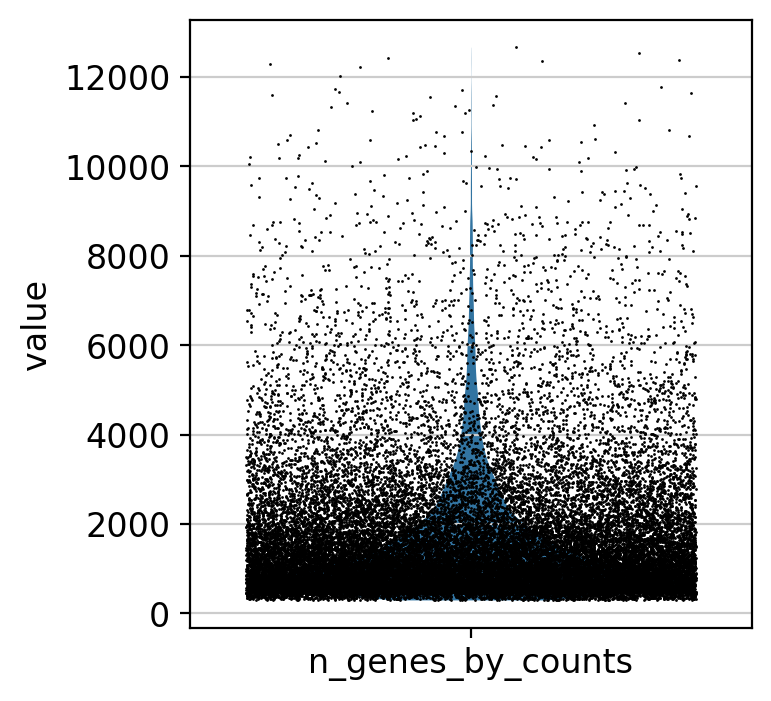

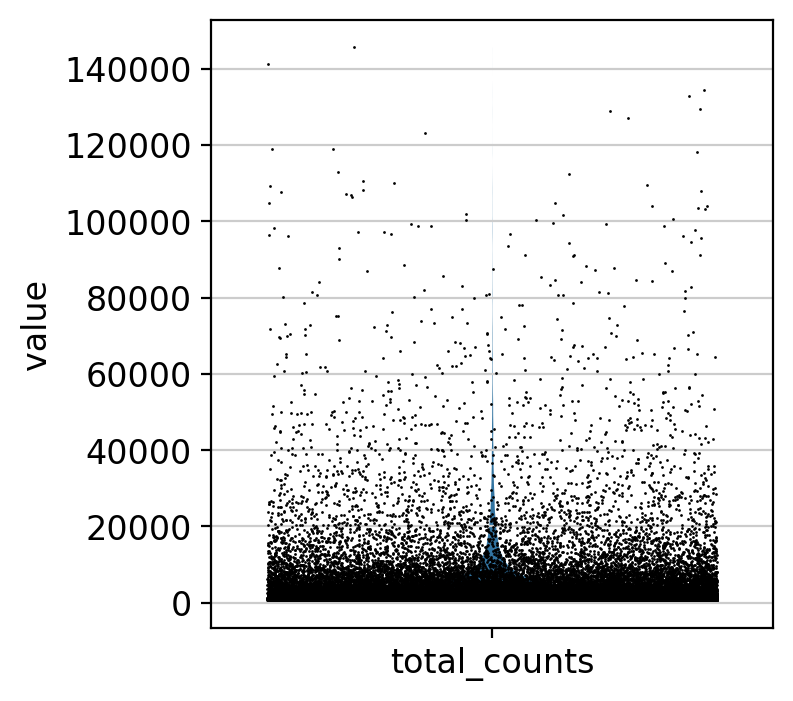

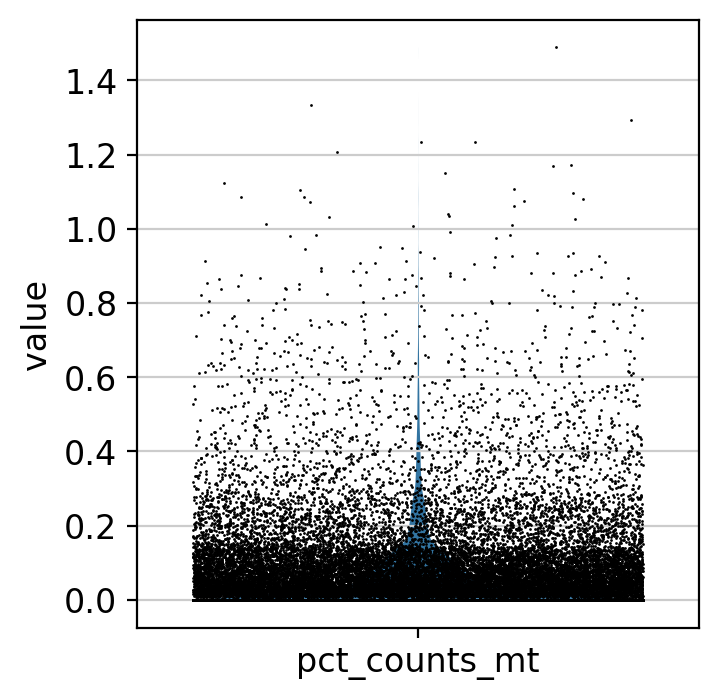

In [ ]:
#Cell Quality Control

adata.var['mt'] = adata.var_names.str.startswith('mt-')
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)

# Scanpy will prepend the string in the save argument with "violin"
# and save it to our figure directory defined in the first step.
sc.pl.violin(adata, ['n_genes_by_counts'], jitter=0.4)
sc.pl.violin(adata, ['total_counts'], jitter=0.4)
sc.pl.violin(adata, ['pct_counts_mt'], jitter=0.4)

In [ ]:
# Check if mitochondrial genes were actually identified
print(f"Number of MT genes found: {adata.var['mt'].sum()}")
print(f"Total genes: {adata.n_vars}")

# See which genes were marked as mitochondrial
print("\nMitochondrial genes identified:")
print(adata.var_names[adata.var['mt']].tolist())

# Look at some gene names in your dataset
print("\nFirst 50 gene names:")
print(adata.var_names[:50].tolist())

# Check summary statistics
print("\nMitochondrial content statistics:")
print(adata.obs['pct_counts_mt'].describe())

Number of MT genes found: 12
Total genes: 31859

Mitochondrial genes identified:
['mt-atp6', 'mt-atp8', 'mt-co1', 'mt-co2', 'mt-cyb', 'mt-nd1', 'mt-nd5', 'mt-nd6', 'mt-nd2', 'mt-nd3', 'mt-nd4', 'mt-nd4l']

First 50 gene names:
['a1cf', 'a2ml', 'aaas', 'aacs', 'aadac', 'aadacl4', 'aadat', 'aagab', 'aak1a', 'aak1b', 'aamdc', 'aamp', 'aanat1', 'aanat2', 'aar2', 'aars', 'aars2', 'aarsd1', 'aasdh', 'aasdhppt', 'aass', 'aatf', 'aatka', 'aatkb', 'abat', 'abca12', 'abca1a', 'abca1b', 'abca2', 'abca3b', 'abca4a', 'abca4b', 'abca5', 'abcb10', 'abcb11a', 'abcb11b', 'abcb4', 'abcb5', 'abcb6a', 'abcb6b', 'abcb7', 'abcb8', 'abcb9', 'abcc1', 'abcc10', 'abcc12', 'abcc13', 'abcc2', 'abcc3', 'abcc4']

Mitochondrial content statistics:
count    36225.000000
mean         0.063207
std          0.112304
min          0.000000
25%          0.000000
50%          0.019212
75%          0.082884
max          1.489506
Name: pct_counts_mt, dtype: float64


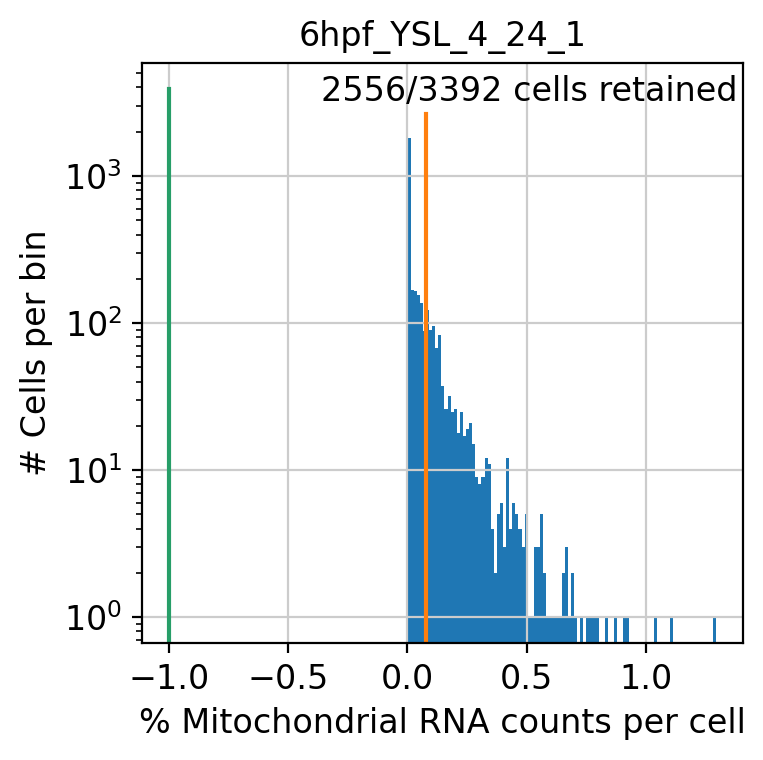

Mito-Filtering 6hpf_YSL_4_24_1 (2556/3392 cells retained)



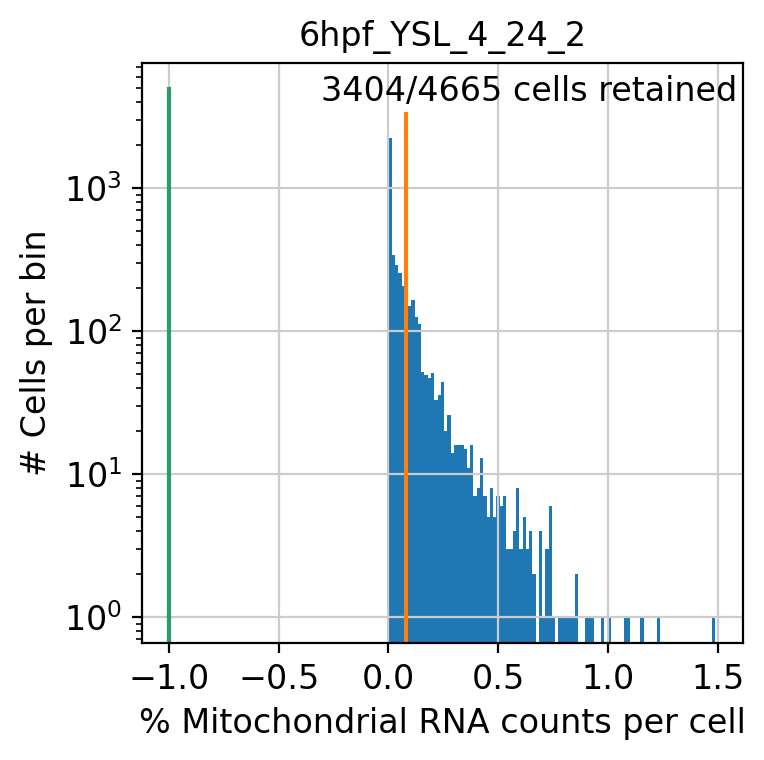

Mito-Filtering 6hpf_YSL_4_24_2 (3404/4665 cells retained)



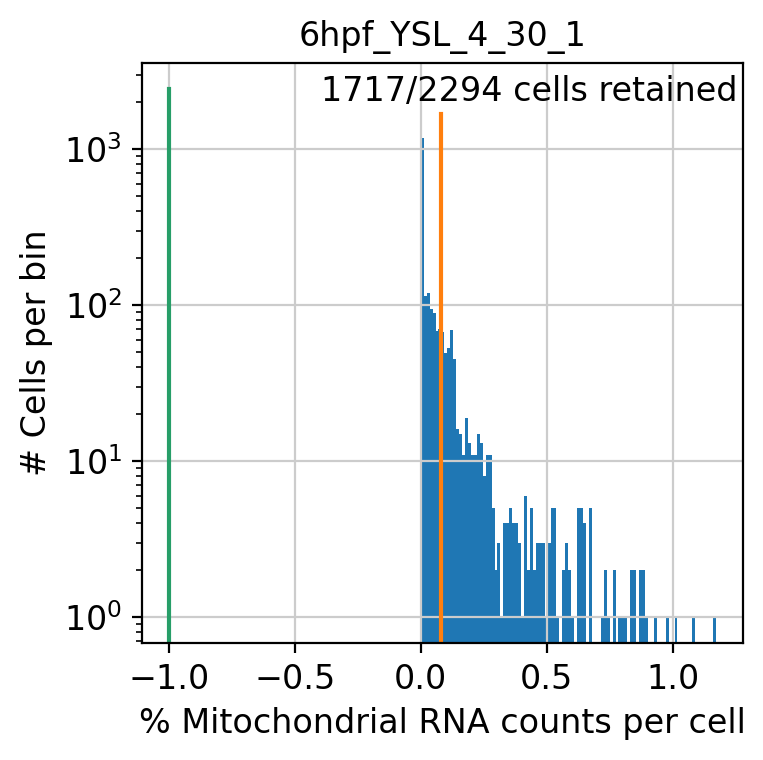

Mito-Filtering 6hpf_YSL_4_30_1 (1717/2294 cells retained)



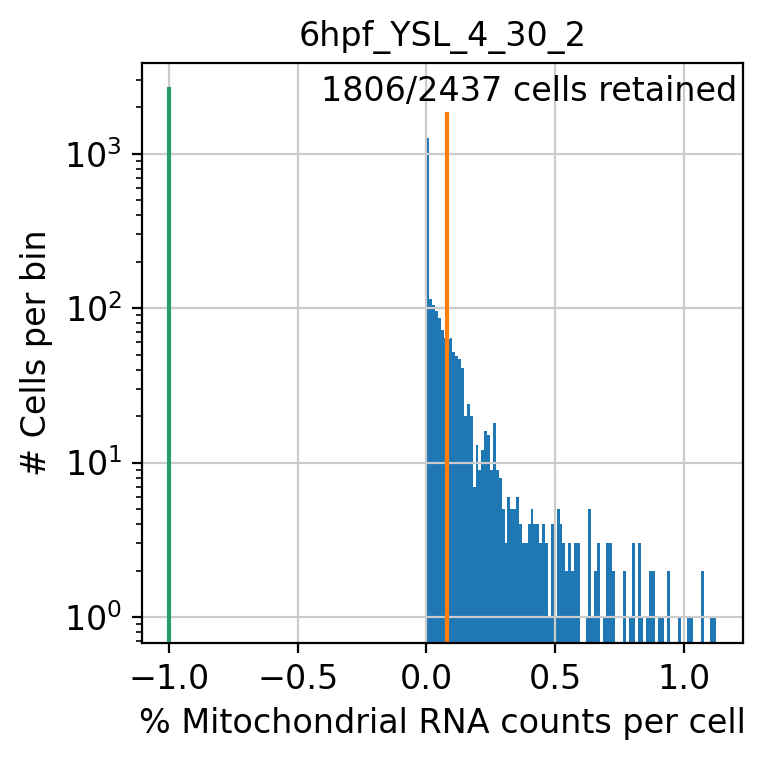

Mito-Filtering 6hpf_YSL_4_30_2 (1806/2437 cells retained)



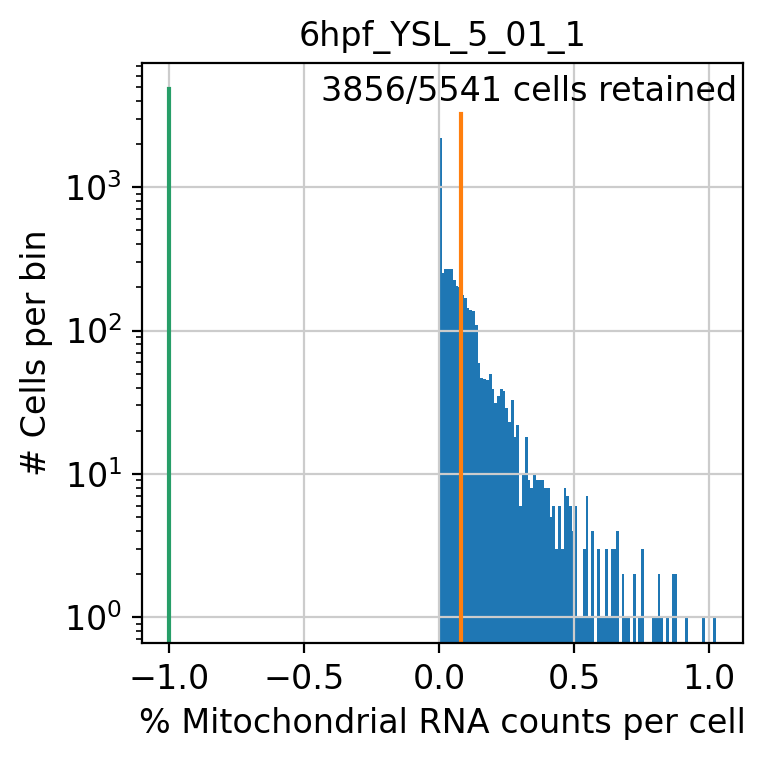

Mito-Filtering 6hpf_YSL_5_01_1 (3856/5541 cells retained)



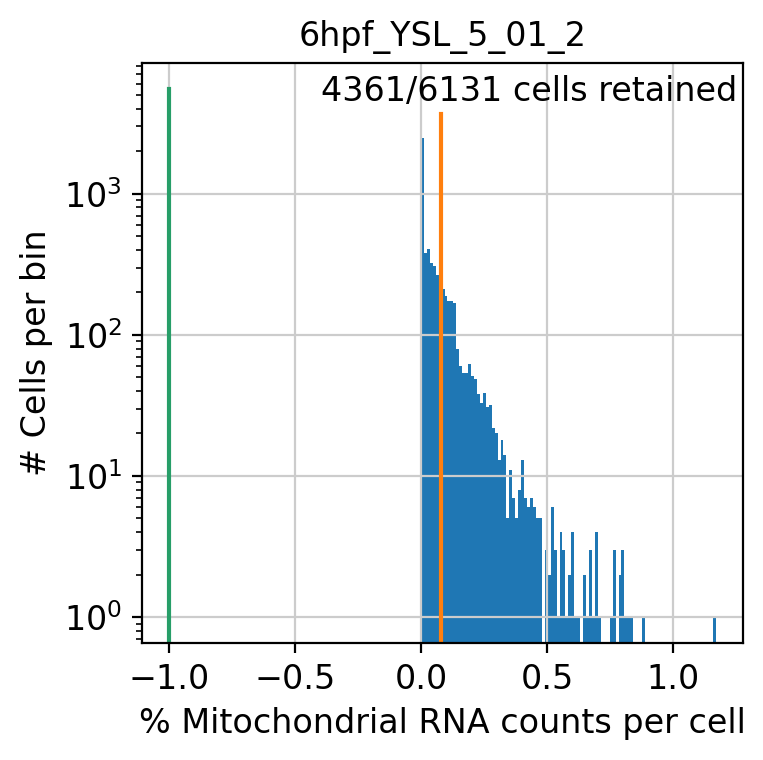

Mito-Filtering 6hpf_YSL_5_01_2 (4361/6131 cells retained)



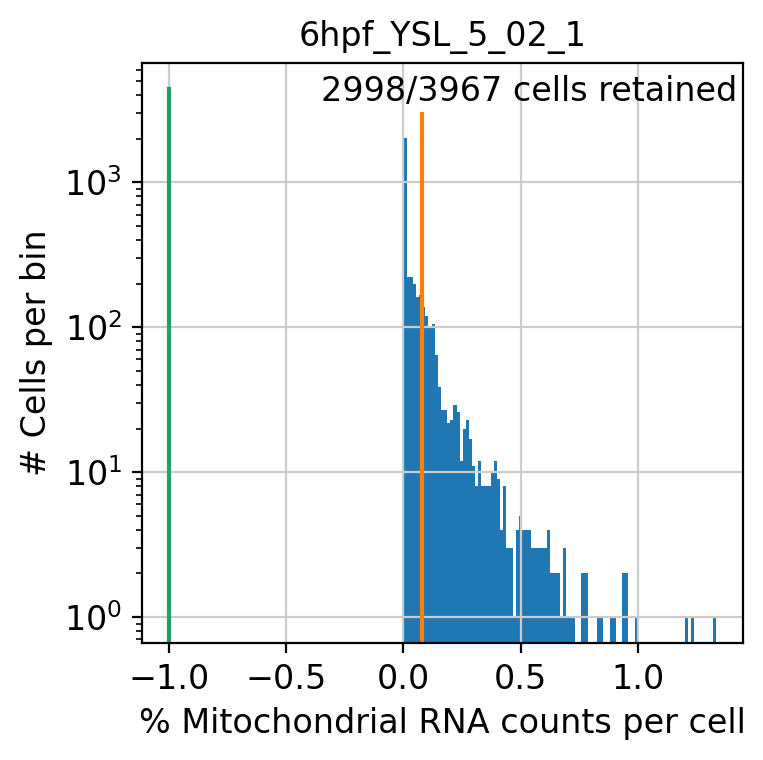

Mito-Filtering 6hpf_YSL_5_02_1 (2998/3967 cells retained)



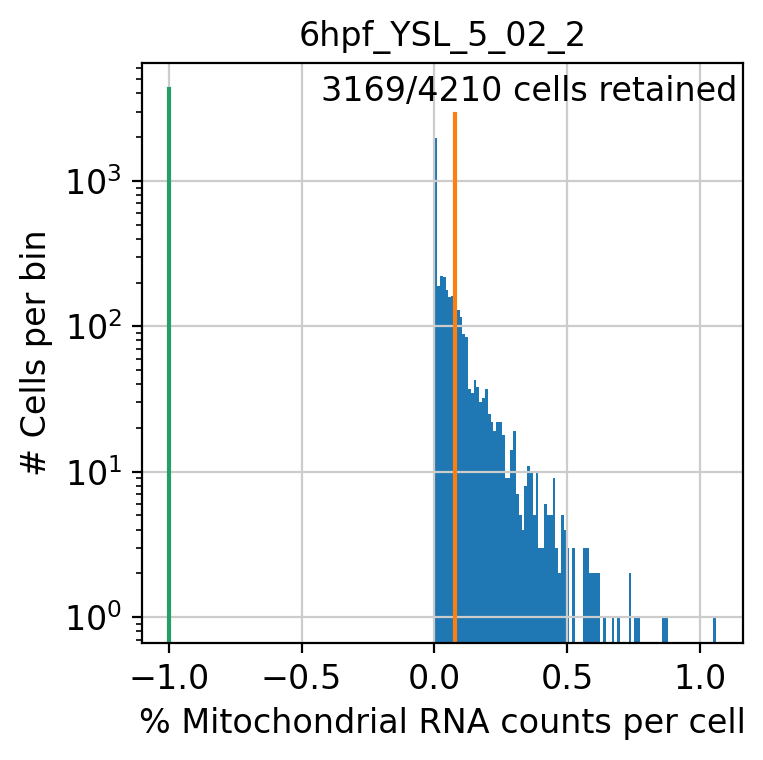

Mito-Filtering 6hpf_YSL_5_02_2 (3169/4210 cells retained)



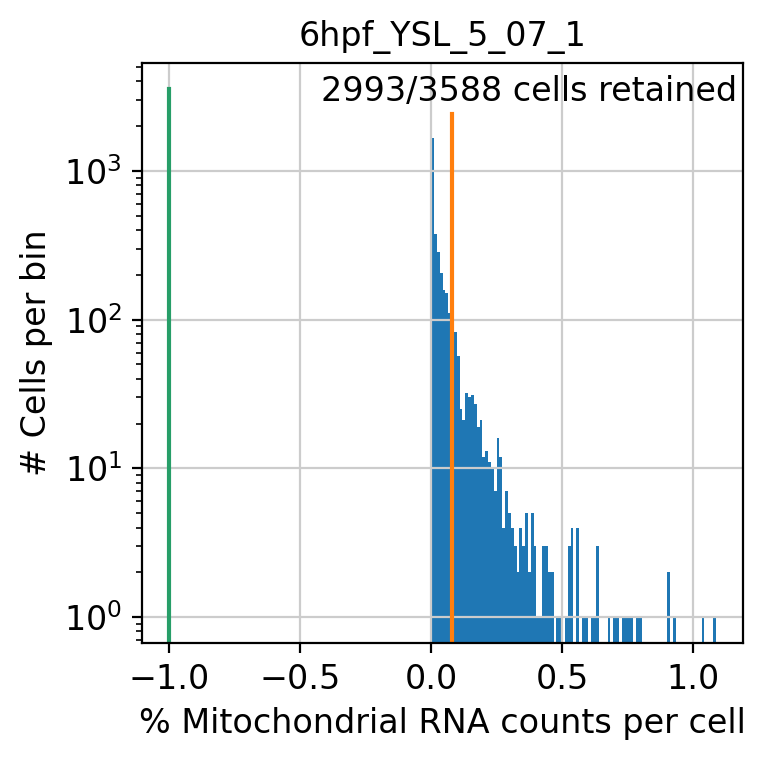

Mito-Filtering 6hpf_YSL_5_07_1 (2993/3588 cells retained)


=== Summary ===
Original cells: 36225
Filtered cells: 26860
Cells removed: 9365
Retention rate: 74.1%


In [ ]:
# Define thresholds for each sample
sample_thresholds = {
    '6hpf_YSL_4_24_1': {'lower': -1, 'upper': 0.08},
    '6hpf_YSL_4_24_2': {'lower': -1, 'upper': 0.08},
    '6hpf_YSL_4_30_1': {'lower': -1, 'upper': 0.08},
    '6hpf_YSL_4_30_2': {'lower': -1, 'upper': 0.08},
    '6hpf_YSL_5_01_1': {'lower': -1, 'upper': 0.08},
    '6hpf_YSL_5_01_2': {'lower': -1, 'upper': 0.08},
    '6hpf_YSL_5_02_1': {'lower': -1, 'upper': 0.08},
    '6hpf_YSL_5_02_2': {'lower': -1, 'upper': 0.08},
    '6hpf_YSL_5_07_1': {'lower': -1, 'upper': 0.08}
}

# Get unique sample IDs from the 'sample' column
samples = adata.obs['sample'].unique()

# Store filtered samples
filtered_adatas = []

# Filter each sample separately with custom thresholds
for sample in samples:
    # Subset data for this sample
    adata_sample = adata[adata.obs['sample'] == sample].copy()

    # Set library_id for the function
    adata_sample.uns['library_id'] = sample

    # Get thresholds for this sample
    thresholds = sample_thresholds[sample]

    # Apply filtering with sample-specific thresholds and capture the result
    adata_sample = zmap.pp.filter_mito(
        adata_sample,
        filter_cells=True,
        library_id=sample,
        lower_threshold=thresholds['lower'],
        upper_threshold=thresholds['upper']
    )

    # Store the filtered sample
    filtered_adatas.append(adata_sample)

# Combine all filtered samples back together
adata_filtered = ad.concat(filtered_adatas, join='outer')

print(f"\n=== Summary ===")
print(f"Original cells: {adata.n_obs}")
print(f"Filtered cells: {adata_filtered.n_obs}")
print(f"Cells removed: {adata.n_obs - adata_filtered.n_obs}")
print(f"Retention rate: {100 * adata_filtered.n_obs / adata.n_obs:.1f}%")

In [ ]:
adata = adata_filtered

#Doublet Filtering

In [ ]:
adata

AnnData object with n_obs × n_vars = 26860 × 31859
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'n_genes', 'total_counts', 'sample_prep', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo'

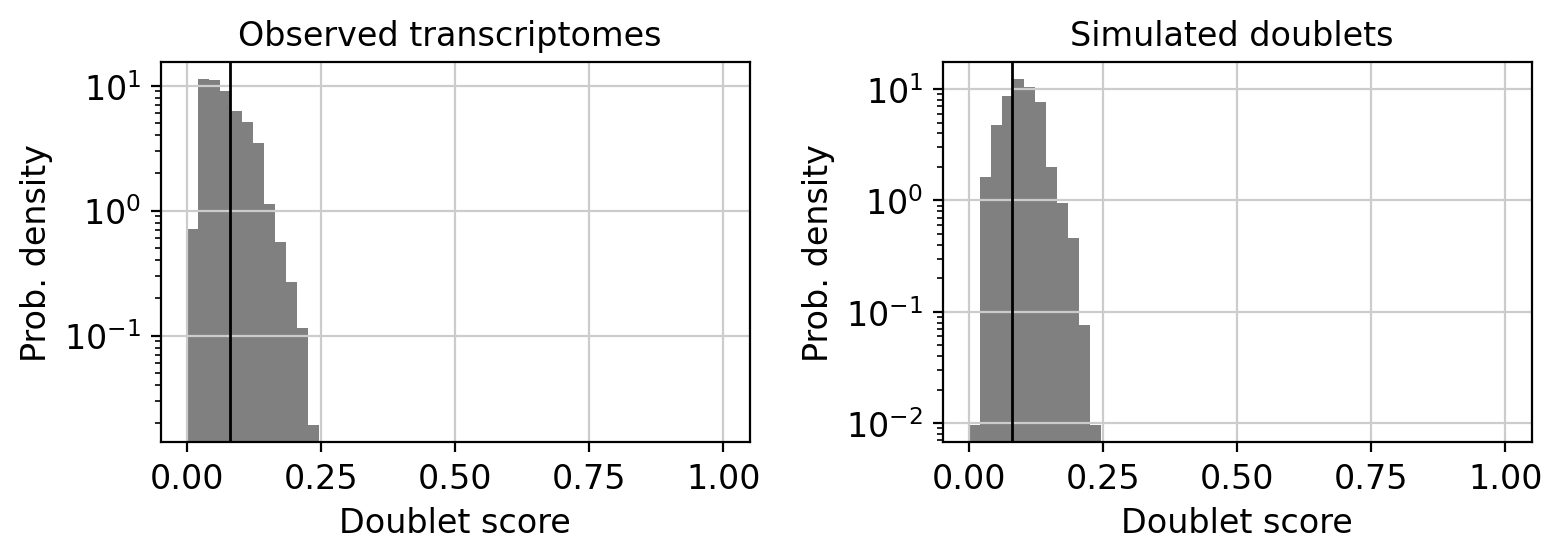

Doublet Filtering 6hpf_YSL_4_24_1 (1678/2556 cells retained)



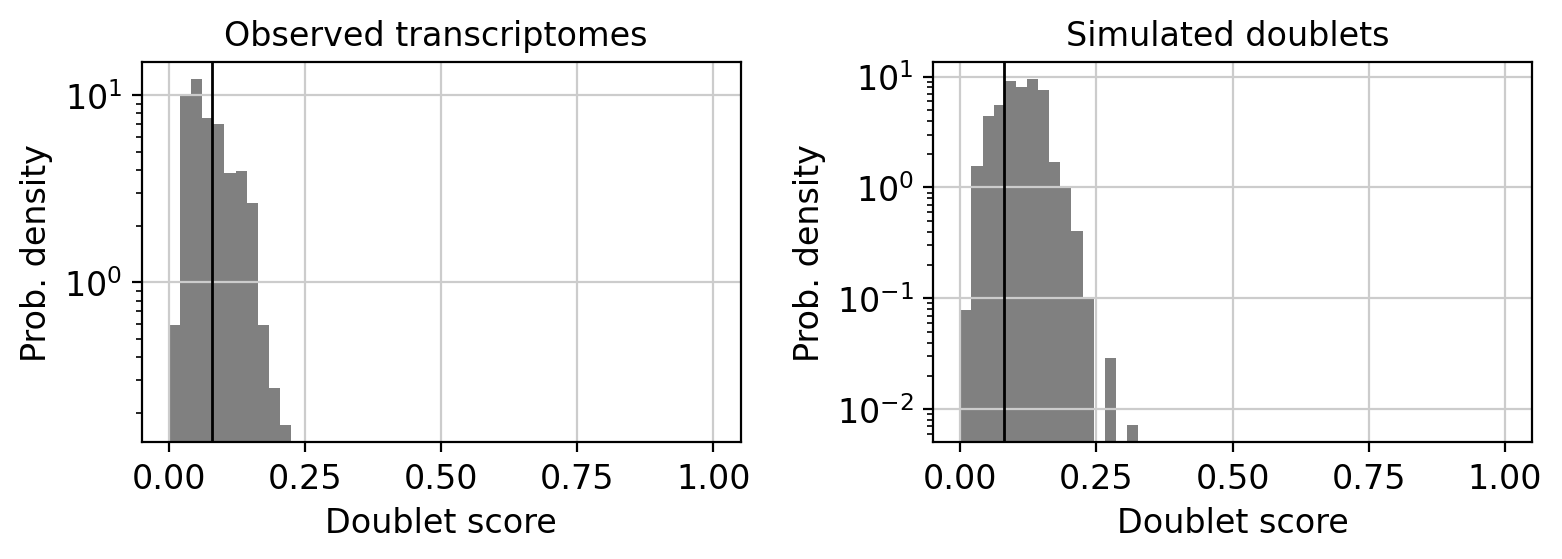

Doublet Filtering 6hpf_YSL_4_24_2 (2118/3404 cells retained)



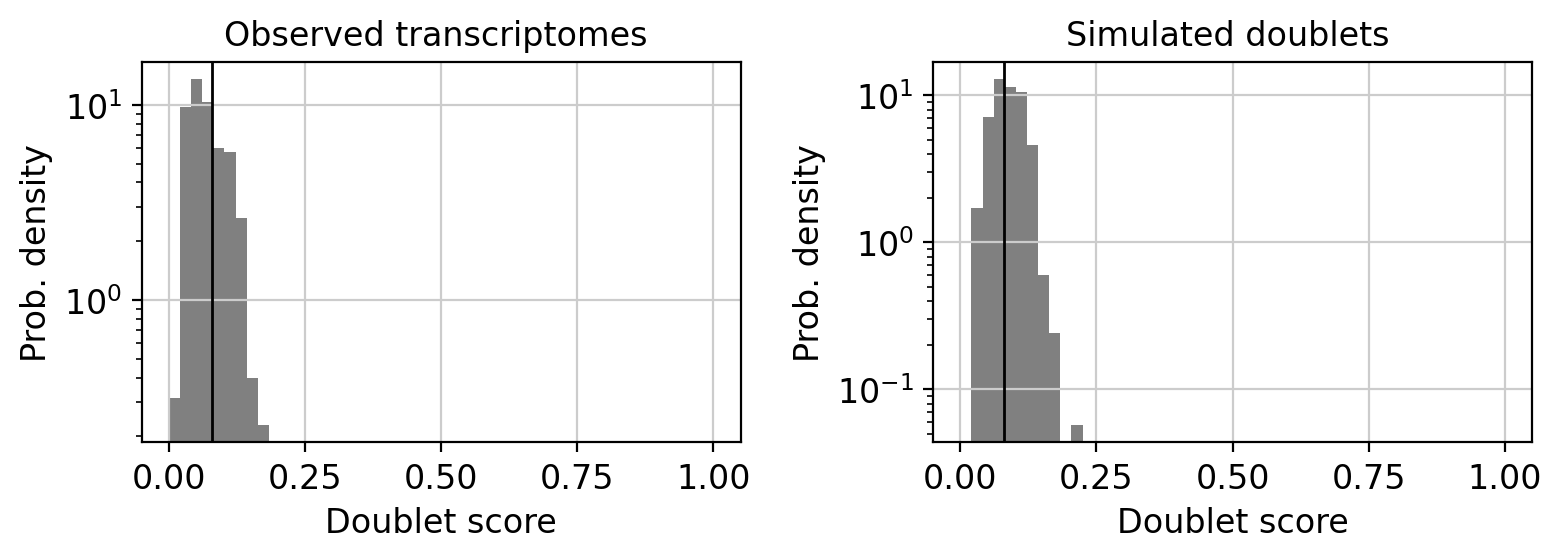

Doublet Filtering 6hpf_YSL_4_30_1 (1107/1717 cells retained)



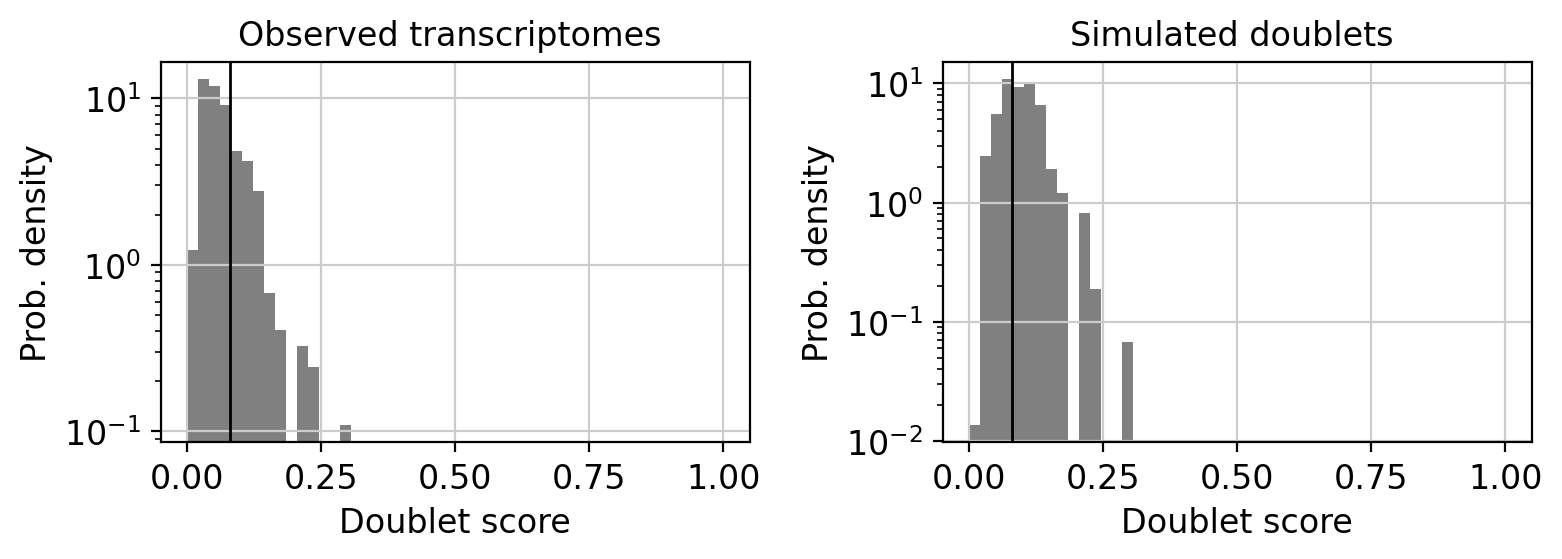

Doublet Filtering 6hpf_YSL_4_30_2 (1206/1806 cells retained)



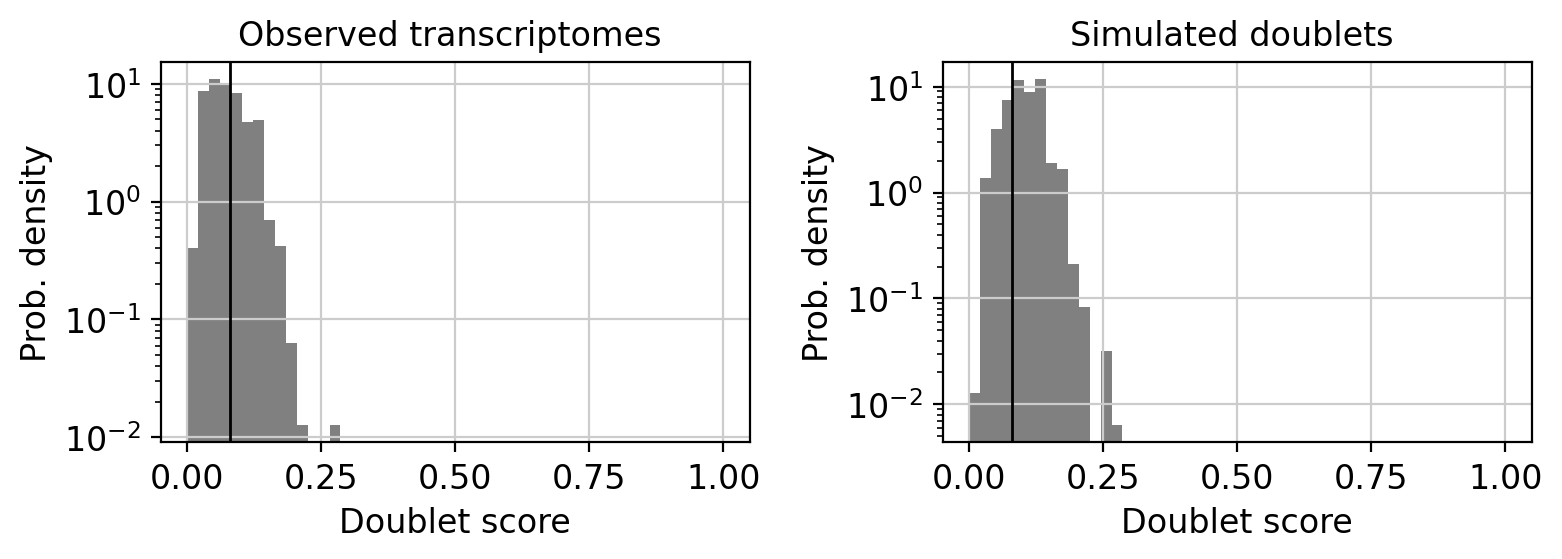

Doublet Filtering 6hpf_YSL_5_01_1 (2163/3856 cells retained)



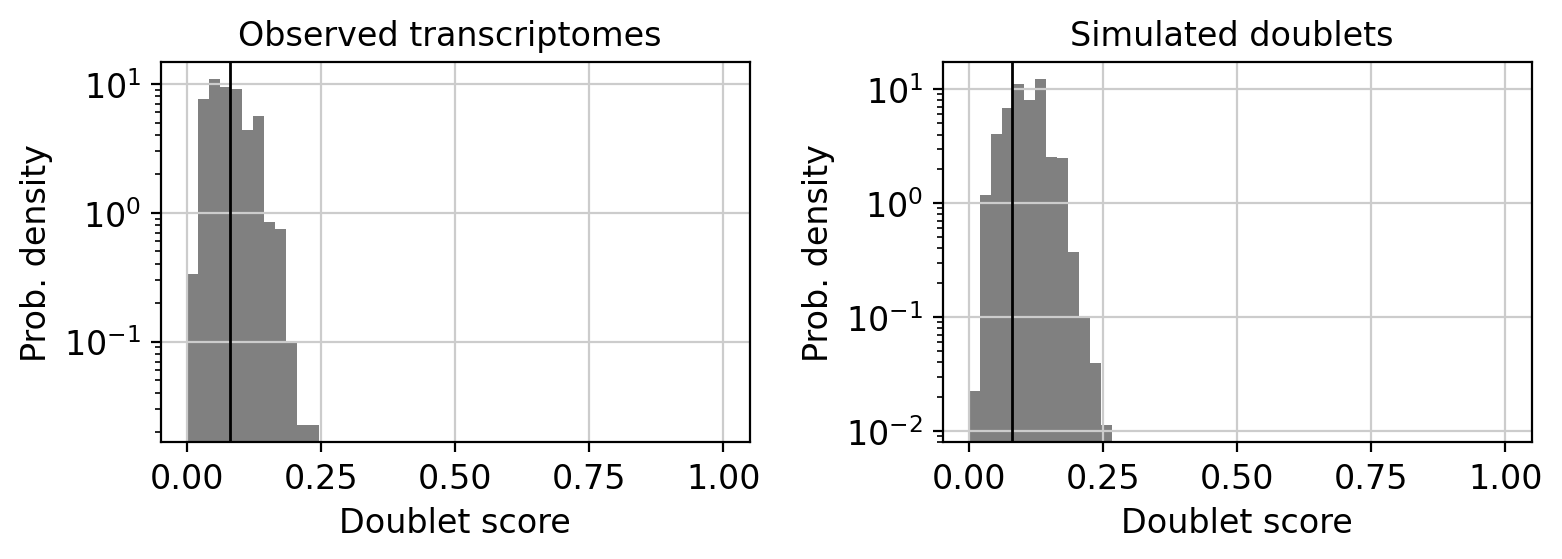

Doublet Filtering 6hpf_YSL_5_01_2 (2516/4361 cells retained)



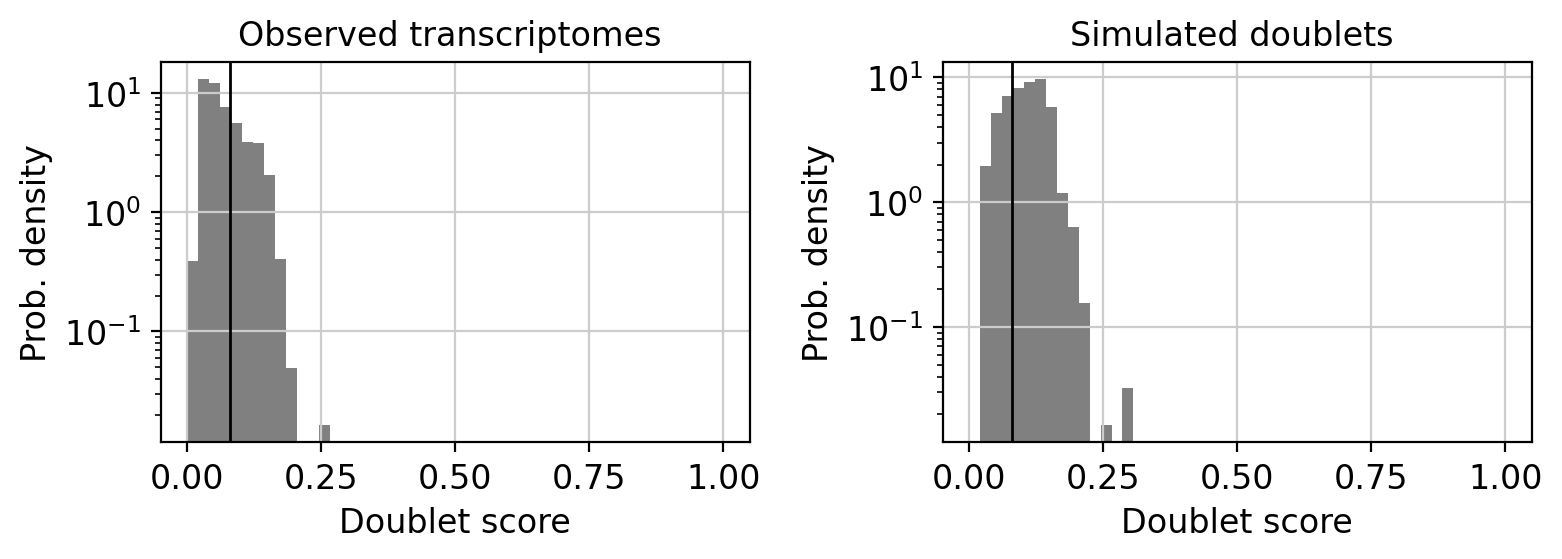

Doublet Filtering 6hpf_YSL_5_02_1 (1935/2998 cells retained)



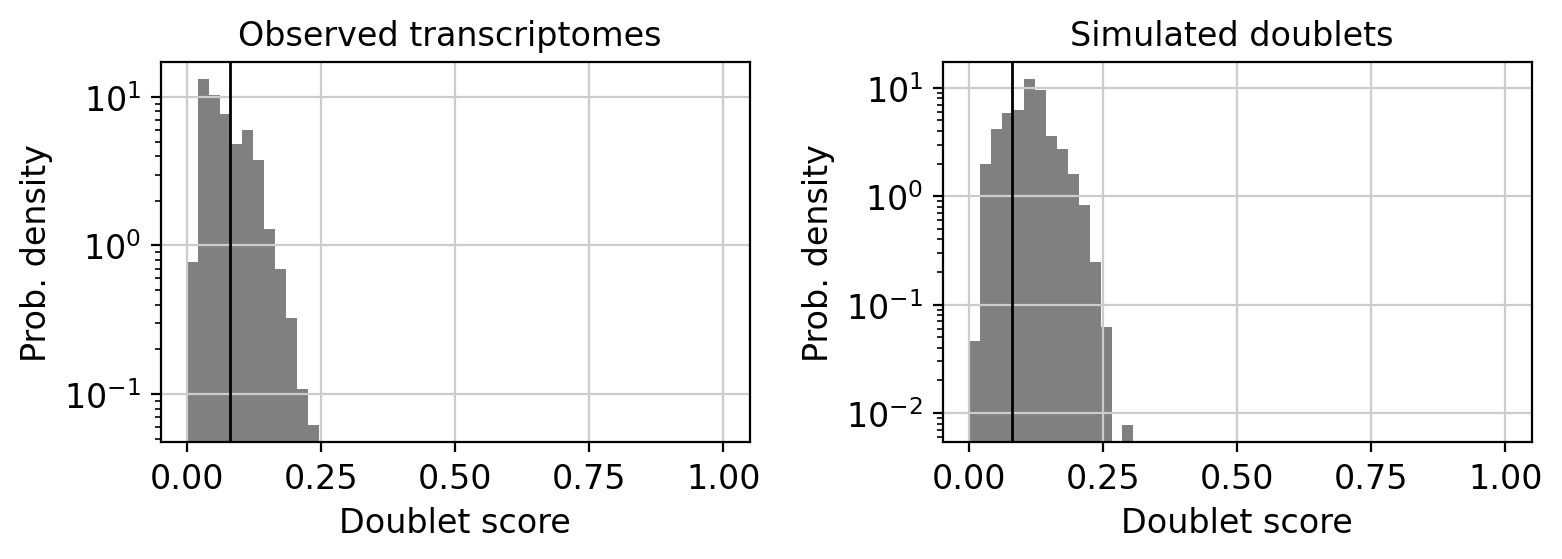

Doublet Filtering 6hpf_YSL_5_02_2 (2068/3169 cells retained)



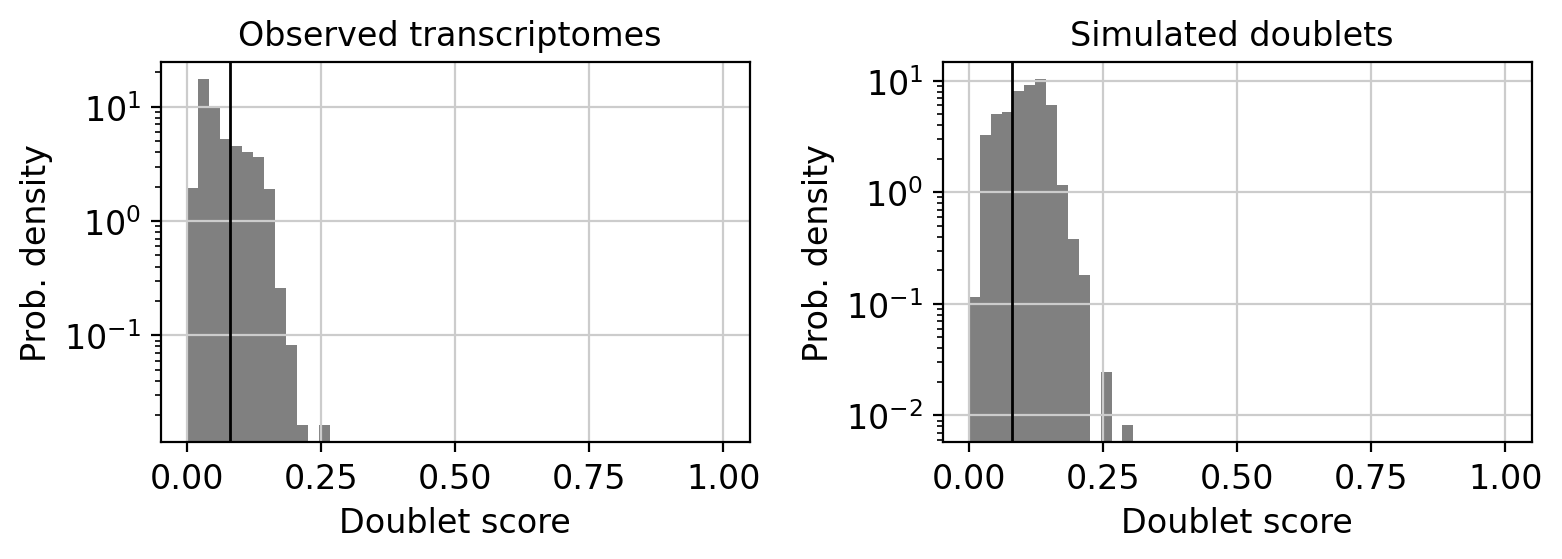

Doublet Filtering 6hpf_YSL_5_07_1 (2038/2993 cells retained)


=== Summary ===
Original cells: 26860
Filtered cells: 16829
Cells removed: 10031
Retention rate: 62.7%


In [ ]:
# Define thresholds for each sample
sample_thresholds = {
    '6hpf_YSL_4_24_1': .08,
    '6hpf_YSL_4_24_2': .08,
    '6hpf_YSL_4_30_1': .08,
    '6hpf_YSL_4_30_2': .08,
    '6hpf_YSL_5_01_1': .08,
    '6hpf_YSL_5_01_2': .08,
    '6hpf_YSL_5_02_1': .08,
    '6hpf_YSL_5_02_2': .08,
    '6hpf_YSL_5_07_1': .08
}

# Get unique sample IDs from the 'sample' column
samples = adata.obs['sample'].unique()

# Store filtered samples
filtered_adatas = []

# Filter each sample separately with custom thresholds
for sample in samples:
    # Subset data for this sample
    adata_sample = adata[adata.obs['sample'] == sample].copy()

    # Set library_id for the function
    adata_sample.uns['library_id'] = sample

    # Get thresholds for this sample
    threshold = sample_thresholds[sample]

    # Apply filtering with sample-specific thresholds and capture the result
    adata_sample = zmap.pp.filter_scrublet(
        adata_sample,
        filter_cells=True,
        threshold=threshold
    )

    # Store the filtered sample
    filtered_adatas.append(adata_sample)

# Combine all filtered samples back together
adata_filtered = ad.concat(filtered_adatas, join='outer')

print(f"\n=== Summary ===")
print(f"Original cells: {adata.n_obs}")
print(f"Filtered cells: {adata_filtered.n_obs}")
print(f"Cells removed: {adata.n_obs - adata_filtered.n_obs}")
print(f"Retention rate: {100 * adata_filtered.n_obs / adata.n_obs:.1f}%")

In [ ]:
adata_filtered

AnnData object with n_obs × n_vars = 16829 × 31859
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'n_genes', 'total_counts', 'sample_prep', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet'

In [ ]:
adata = adata_filtered

In [ ]:
adata

AnnData object with n_obs × n_vars = 16829 × 31859
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'n_genes', 'total_counts', 'sample_prep', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet'

#Ribo Filtering

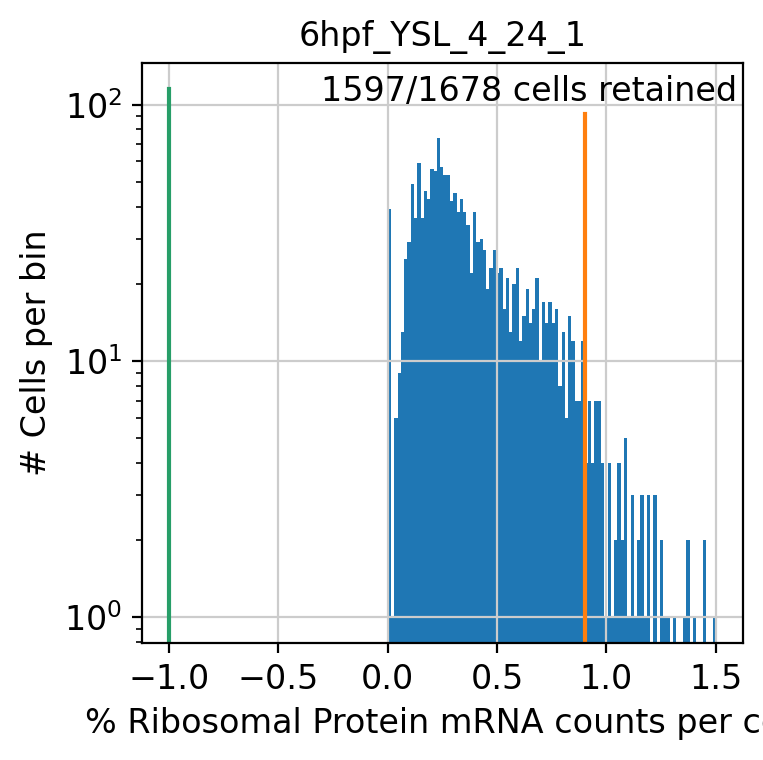

Ribo-Filtering 6hpf_YSL_4_24_1 (1597/1678 cells retained)



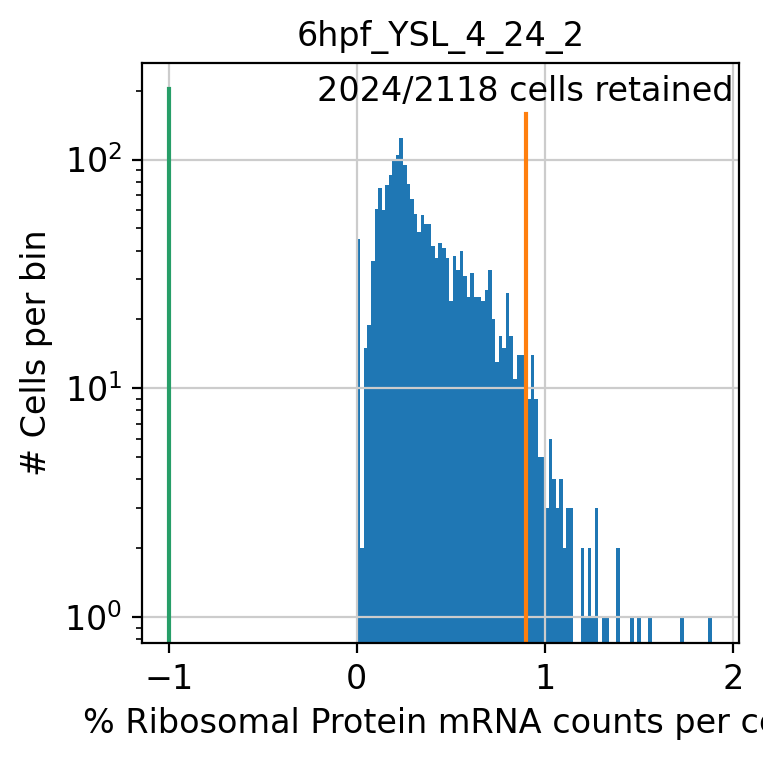

Ribo-Filtering 6hpf_YSL_4_24_2 (2024/2118 cells retained)



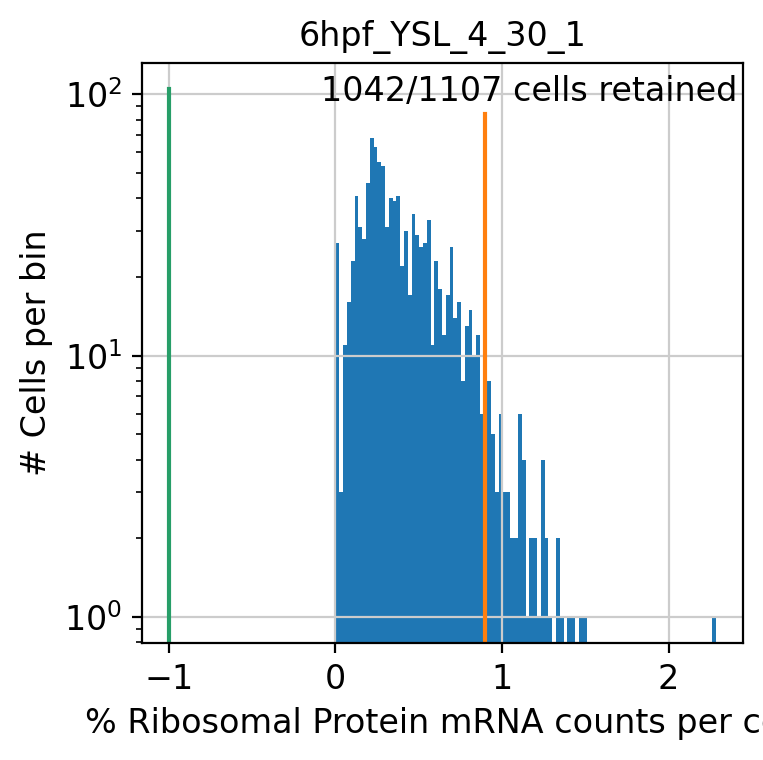

Ribo-Filtering 6hpf_YSL_4_30_1 (1042/1107 cells retained)



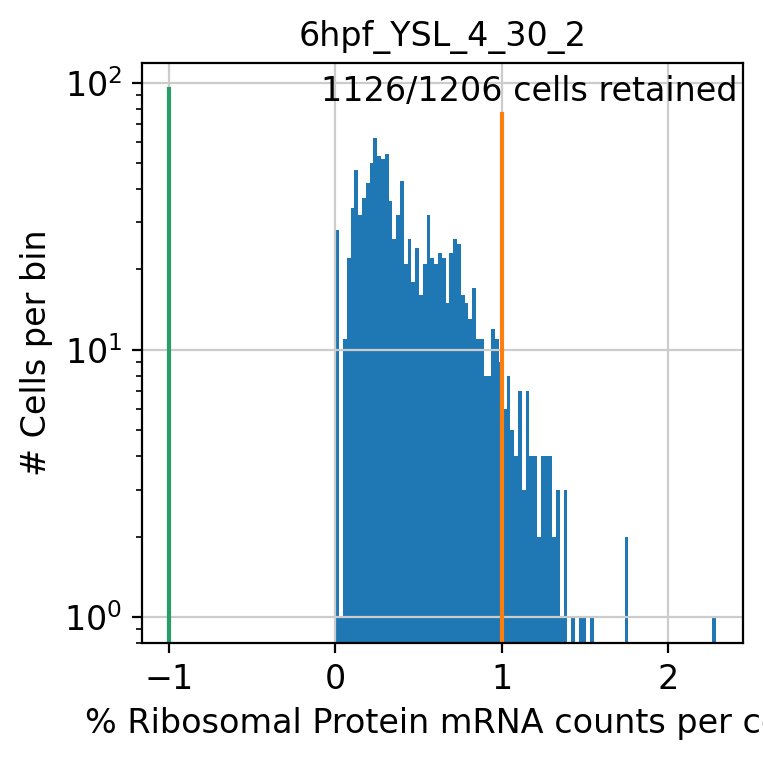

Ribo-Filtering 6hpf_YSL_4_30_2 (1126/1206 cells retained)



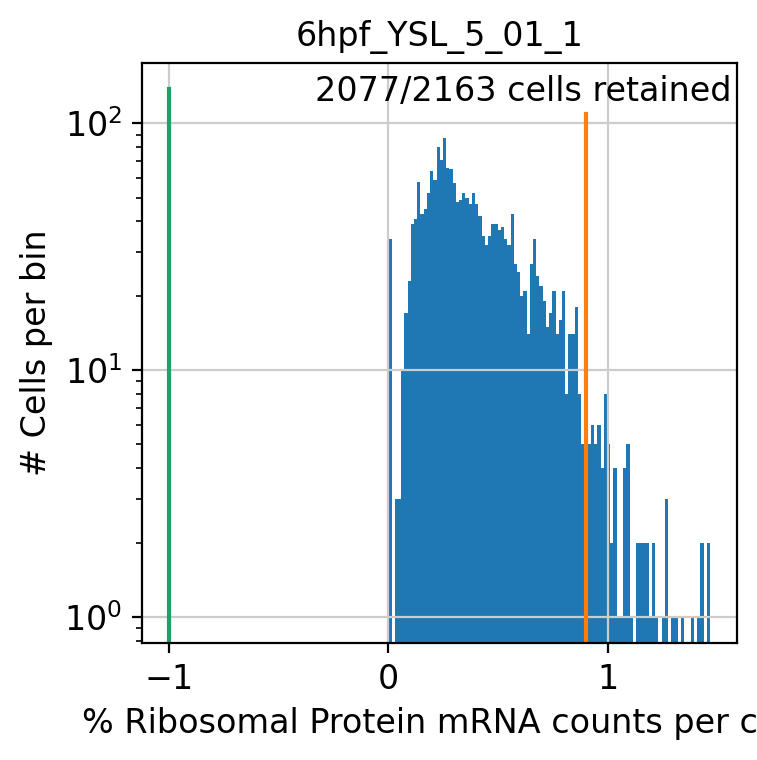

Ribo-Filtering 6hpf_YSL_5_01_1 (2077/2163 cells retained)



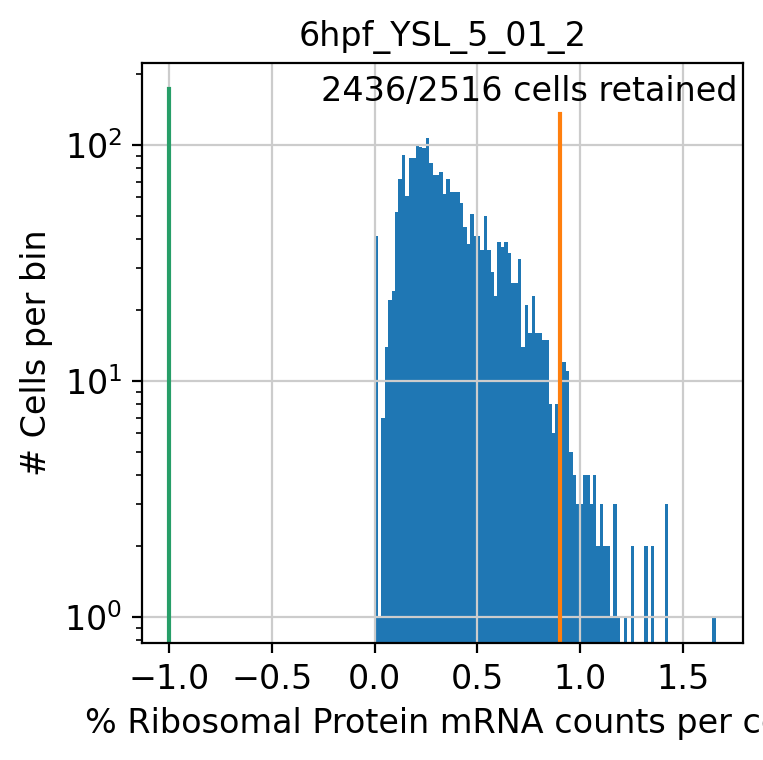

Ribo-Filtering 6hpf_YSL_5_01_2 (2436/2516 cells retained)



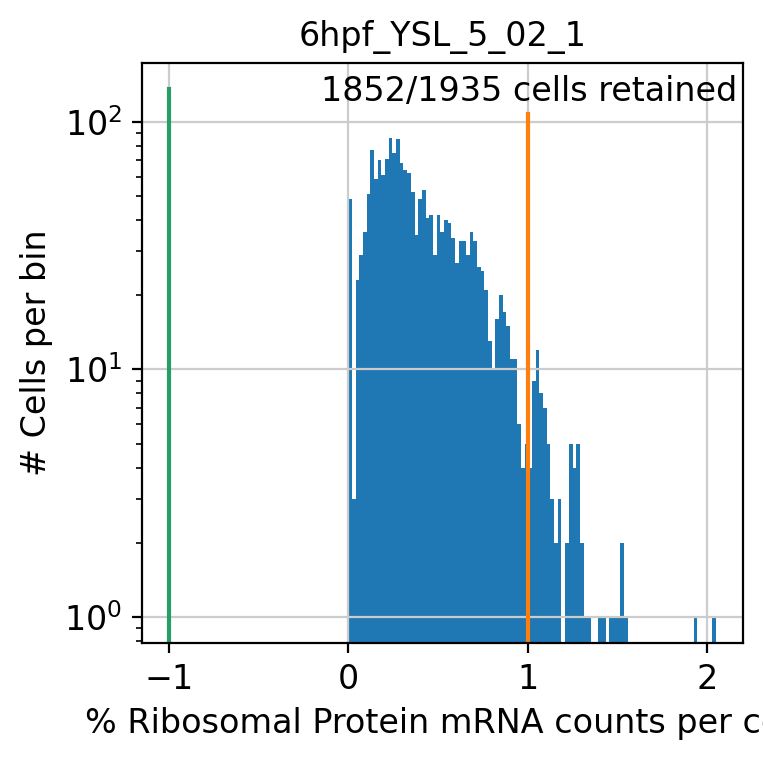

Ribo-Filtering 6hpf_YSL_5_02_1 (1852/1935 cells retained)



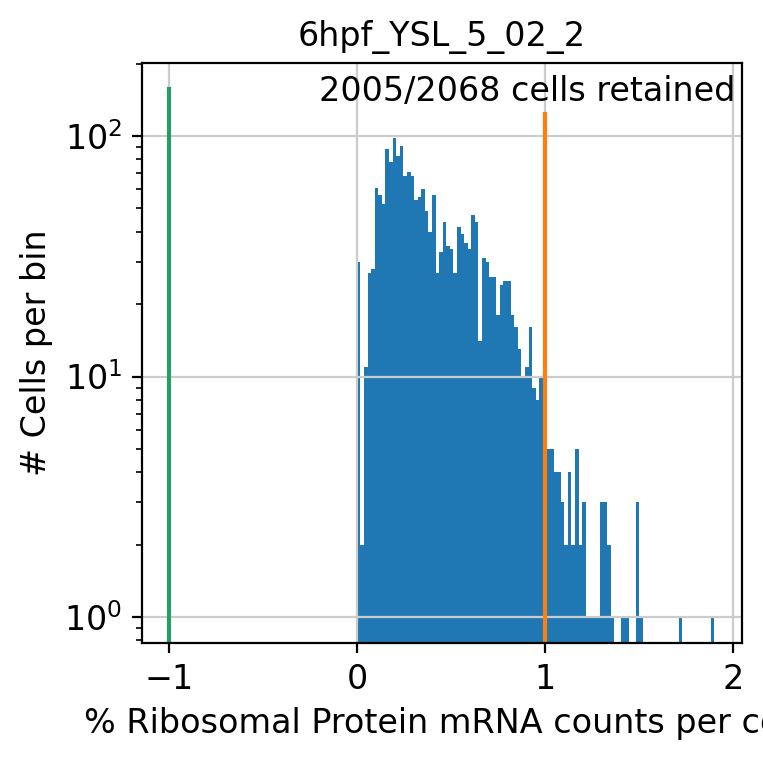

Ribo-Filtering 6hpf_YSL_5_02_2 (2005/2068 cells retained)



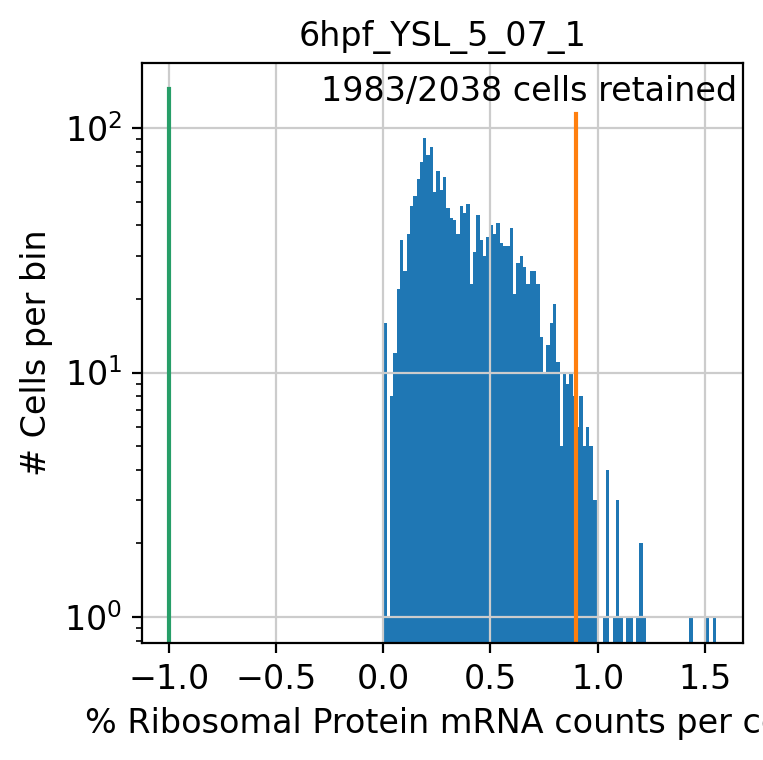

Ribo-Filtering 6hpf_YSL_5_07_1 (1983/2038 cells retained)


=== Summary ===
Original cells: 16829
Filtered cells: 16142
Cells removed: 687
Retention rate: 95.9%


In [ ]:
# Define thresholds for each sample
sample_thresholds = {
    '6hpf_YSL_4_24_1': {'lower': -1, 'upper': 0.9},
    '6hpf_YSL_4_24_2': {'lower': -1, 'upper': 0.9},
    '6hpf_YSL_4_30_1': {'lower': -1, 'upper': 0.9},
    '6hpf_YSL_4_30_2': {'lower': -1, 'upper': 1.0},
    '6hpf_YSL_5_01_1': {'lower': -1, 'upper': 0.9},
    '6hpf_YSL_5_01_2': {'lower': -1, 'upper': 0.9},
    '6hpf_YSL_5_02_1': {'lower': -1, 'upper': 1.0},
    '6hpf_YSL_5_02_2': {'lower': -1, 'upper': 1.0},
    '6hpf_YSL_5_07_1': {'lower': -1, 'upper': 0.9}
}

# Get unique sample IDs from the 'sample' column
samples = adata.obs['sample'].unique()

# Store filtered samples
filtered_adatas = []

# Filter each sample separately with custom thresholds
for sample in samples:
    # Subset data for this sample
    adata_sample = adata[adata.obs['sample'] == sample].copy()

    # Set library_id for the function
    adata_sample.uns['library_id'] = sample

    # Get thresholds for this sample
    threshold = sample_thresholds[sample]

    # Apply filtering with sample-specific thresholds and capture the result
    adata_sample = zmap.pp.filter_ribo(
        adata_sample,
        filter_cells=True,
        library_id=sample,
        lower_threshold=threshold['lower'],
        upper_threshold=threshold['upper']
    )

    # Store the filtered sample
    filtered_adatas.append(adata_sample)

# Combine all filtered samples back together
adata_filtered = ad.concat(filtered_adatas, join='outer')

print(f"\n=== Summary ===")
print(f"Original cells: {adata.n_obs}")
print(f"Filtered cells: {adata_filtered.n_obs}")
print(f"Cells removed: {adata.n_obs - adata_filtered.n_obs}")
print(f"Retention rate: {100 * adata_filtered.n_obs / adata.n_obs:.1f}%")

In [ ]:
adata = adata_filtered

In [ ]:
adata

AnnData object with n_obs × n_vars = 16142 × 31859
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'n_genes', 'total_counts', 'sample_prep', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet'

# Gene Counts Filtering

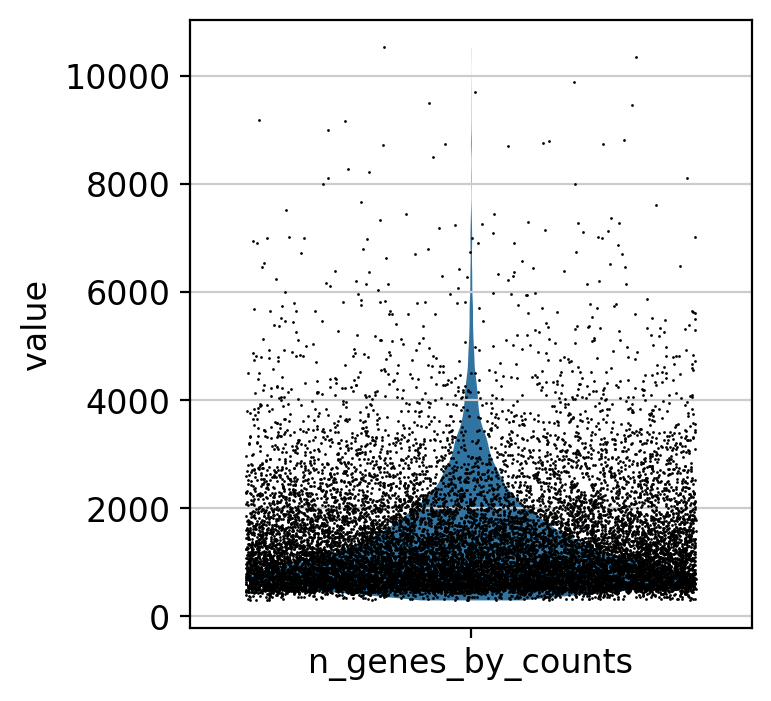

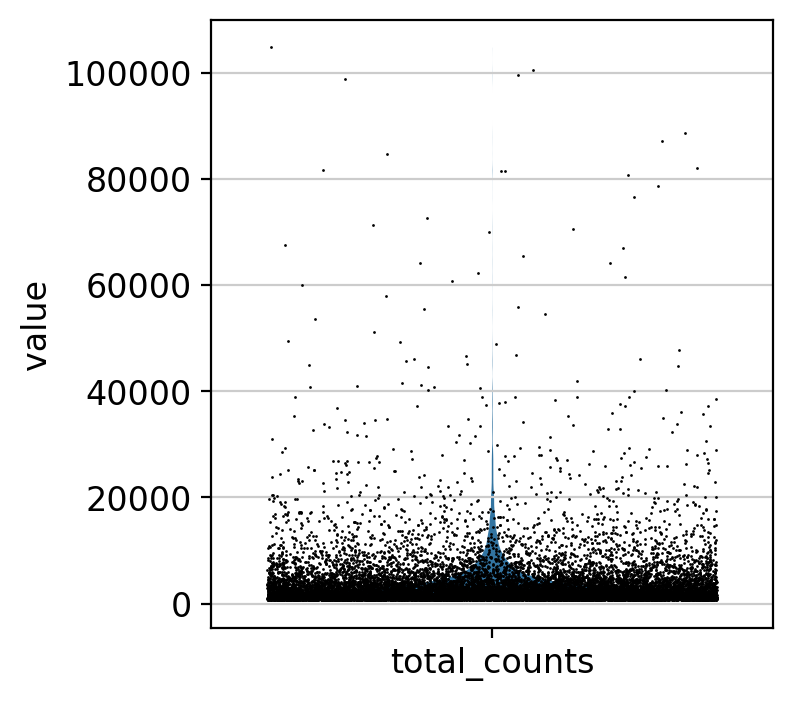

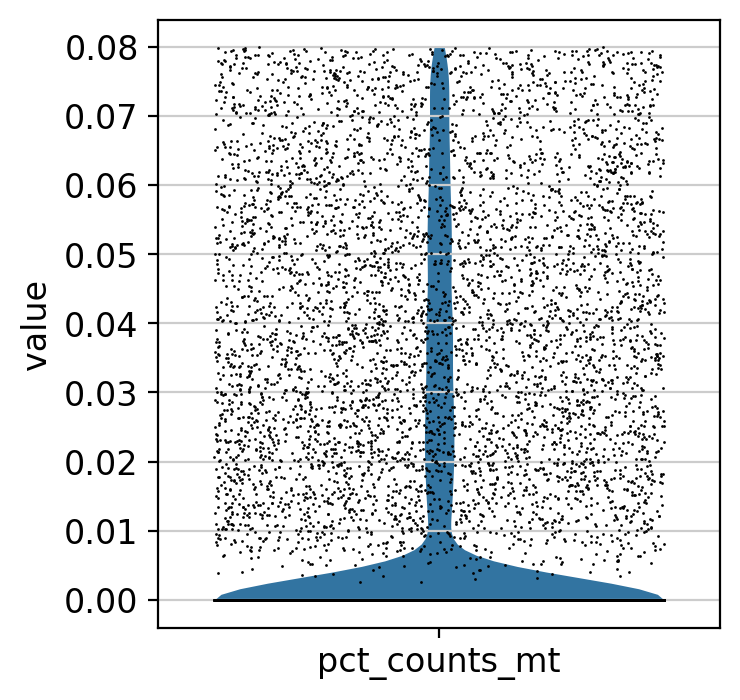

In [ ]:
#Cell Quality Control

adata.var['mt'] = adata.var_names.str.startswith('mt-')
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)

# Scanpy will prepend the string in the save argument with "violin"
# and save it to our figure directory defined in the first step.
sc.pl.violin(adata, ['n_genes_by_counts'], save='_n_genes', jitter=0.4)
sc.pl.violin(adata, ['total_counts'], save='_total_counts', jitter=0.4)
sc.pl.violin(adata, ['pct_counts_mt'], save='_mito_pct', jitter=0.4)

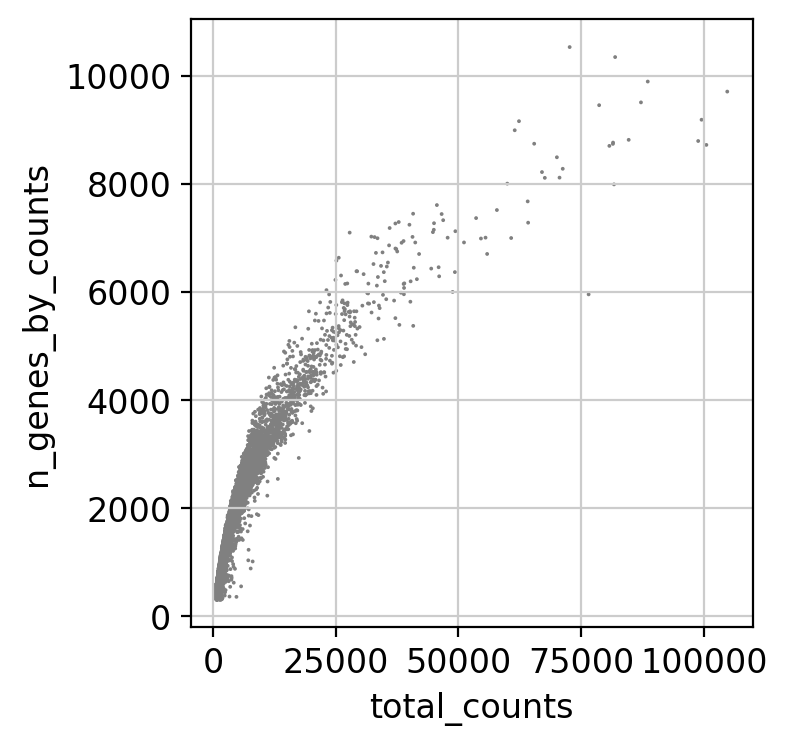

median transcript count per cell: 1891.0
median gene count per cell: 1066.5


In [ ]:
#Visualize filtered data

sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts', save='_gene_vs_transcript_counts')
print('median transcript count per cell: ' + str(adata.obs['tscp_count'].median(0)))
print('median gene count per cell: ' + str(adata.obs['gene_count'].median(0)))

In [ ]:
adata_1k = adata[adata.obs['n_genes_by_counts']>1000]

In [ ]:
adata = adata_1k

In [ ]:
adata_8k = adata[adata.obs['n_genes_by_counts']<6000]

In [ ]:
adata = adata_8k

In [ ]:
adata

View of AnnData object with n_obs × n_vars = 8636 × 31859
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'n_genes', 'total_counts', 'sample_prep', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

#Normalization & Scaling

In [ ]:
adata.layers['raw_nolog'] = adata.X.copy()
adata.layers['raw'] = np.log1p(adata.X.copy())
sc.pp.normalize_total(adata, target_sum=1e6, inplace=True)
adata.layers['tpm_nolog'] = adata.X.copy()
sc.pp.log1p(adata)
adata.layers['tpm'] = adata.X.copy()
adata.raw = adata.copy()
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
sc.pp.regress_out(adata, ["n_genes_by_counts"])
sc.pp.scale(adata)

# Embedding and Leiden Clustering

In [ ]:
def get_significant_pcs(adata, n_iter = 1, n_comps_test = 100, threshold_method='95', show_plots=True):

    adata_tmp = sc.AnnData(adata[:,adata.var.highly_variable].X)

    # Get eigenvalues from data matrix
    print('Performing PCA on data matrix')
    sc.pp.pca(adata_tmp, n_comps=n_comps_test)
    data = adata_tmp.uns['pca']['variance']

    # Get eigenvalues from randomly permuted data matrices
    print('Performing PCA on randomized data matrices')
    data_rand = []
    data_rand_max = []
    nPCs_above_rand = []
    for j in range(n_iter):
        sys.stdout.write('\rIteration %i / %i' % (j+1, n_iter)); sys.stdout.flush()
        #print('Iteration', j+1, '/', n_iter, end='\r')
        np.random.seed(seed=j)
        adata_tmp_rand = adata_tmp.copy()
        mat = adata_tmp_rand.X
        for c in range(mat.shape[1]):
            mat[:,c] = mat[np.random.permutation(mat.shape[0]),c]
        adata_tmp_rand.X = mat
        sc.pp.pca(adata_tmp_rand, n_comps=n_comps_test)
        data_rand_next = adata_tmp_rand.uns['pca']['variance']
        data_rand.extend(data_rand_next.tolist())
        data_rand_max.append(np.max(data_rand_next))
        nPCs_above_rand.append(np.count_nonzero(data>np.max(data_rand_next)))

    # Set eigenvalue thresholding method
    if threshold_method == '95':
        method_string = 'Counting the # of PCs with eigenvalues above random in >95% of trials'
        thresh = np.percentile(data_rand_max,95)
    elif threshold_method == 'median':
        method_string = 'Counting the # of PCs with eigenvalues above random in >50% of trials'
        thresh = np.percentile(data_rand_max,50)
    elif threshold_method == 'all':
        method_string = 'Counting the # of PCs with eigenvalues above random across all trials'
        thresh = np.percentile(data_rand_max,100)

    # Determine # of PCs with eigenvalues above threshold
    n_sig_PCs = np.count_nonzero(data>thresh)

    if show_plots:

        # Plot eigenvalue histograms
        bins = np.logspace(0, np.log10(np.max(data)+10), 50)
        sns.histplot(data_rand, bins=bins, kde=False, alpha=1, label='random', stat='probability', color='orange')#, weights=np.zeros_like(data_rand) + 1. / len(data_rand))
        sns.histplot(data, bins=bins, kde=False, alpha=0.5, label='data', stat='probability')#, weights=np.zeros_like(data) + 1. / len(data))
        plt.legend(loc='upper right')
        plt.axvline(x = thresh, color = 'k', linestyle = '--', alpha=0.5, linewidth=1)
        plt.xscale('log')
        #plt.yscale('log')
        plt.xlabel('Eigenvalue')
        plt.ylabel('Frequency')
        plt.show()

        # Plot nPCs above rand histograms
        sns.set_context(rc = {'patch.linewidth': 0.0})
        sns.histplot(nPCs_above_rand, kde=True, stat='probability', color='#1f77b4', binwidth=0.8)
        plt.xlabel('# PCs Above Random')
        plt.ylabel('Frequency')
        plt.xlim([0, n_comps_test])
        plt.show()

        # Plot scree
        plt.plot(adata_tmp.uns['pca']['variance'], alpha=1, label='data')
        plt.plot(adata_tmp_rand.uns['pca']['variance'], alpha=1, label='random')
        plt.legend(loc='upper right')
        plt.axhline(y = thresh, color = 'k', linestyle = '--', alpha=0.5, linewidth=1)
        plt.yscale('log')
        plt.xlabel('PC #')
        plt.ylabel('Eigenvalue')
        plt.show()

        # Plot cumulative histogram
        #cumsum_data = np.cumsum(adata_tmp.uns['pca']['variance'] / sum(adata_tmp.uns['pca']['variance']))
        #cumsum_data_random = np.cumsum(adata_tmp_rand.uns['pca']['variance'] / sum(adata_tmp_rand.uns['pca']['variance']))
        #bin_heights = plt.plot(cumsum_data, alpha=1, label='data')
        #bin_heights = plt.plot(cumsum_data_random, alpha=1, label='random')
        #plt.legend(loc='upper right')
        #plt.axhline(y = 0.99, color = 'k', linestyle = '--', alpha=0.5, linewidth=1)
        #plt.axhline(y = 0.95, color = 'k', linestyle = '--', alpha=0.5, linewidth=1)
        #plt.axhline(y = 0.9, color = 'k', linestyle = '--', alpha=0.5, linewidth=1)
        #plt.gca().set_ylim(top=1.1)
        #plt.xlabel('PC #')
        #plt.ylabel('Cumulative Total Variance')
        ##plt.legend('', frameon=False)
        #plt.legend(loc = 'lower right')
        #plt.show()

    # Print summary stats to screen
    print(method_string)
    print('Eigenvalue Threshold =', np.round(thresh, 2))
    print('# Significant PCs =', n_sig_PCs)

    adata.uns['n_sig_PCs'] = n_sig_PCs

    return adata

Performing PCA on data matrix
Performing PCA on randomized data matrices
Iteration 10 / 10

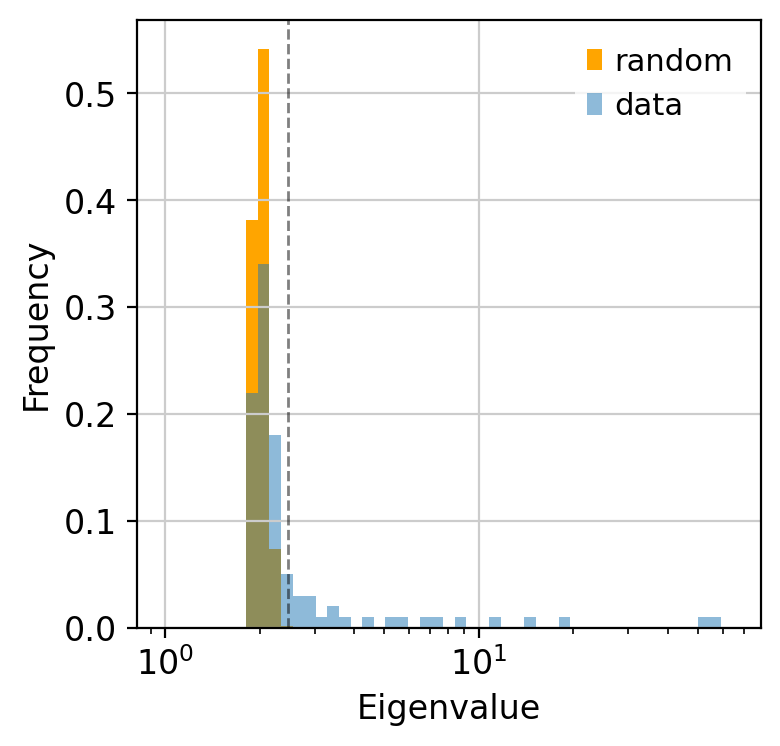

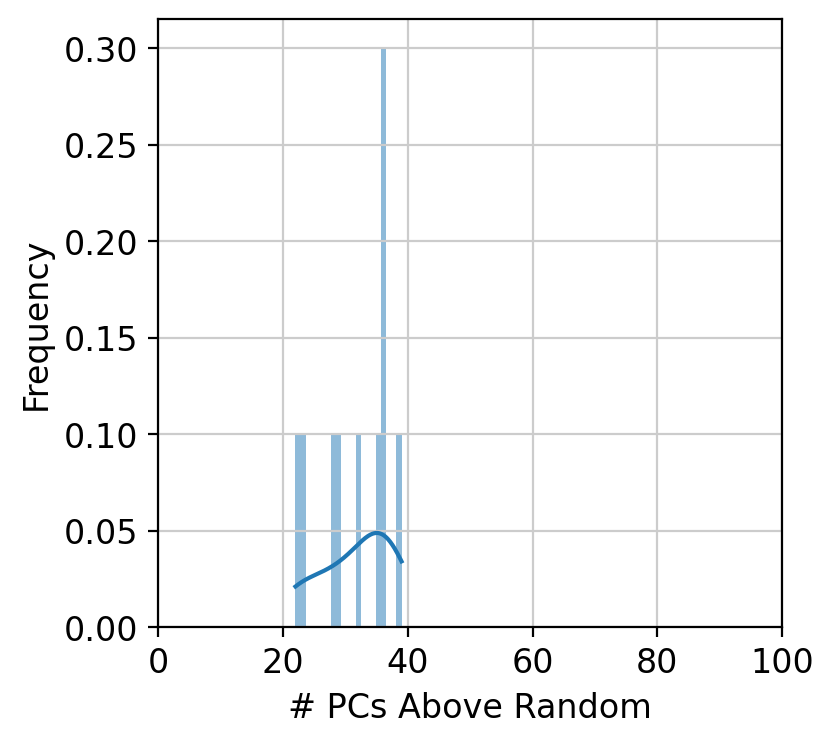

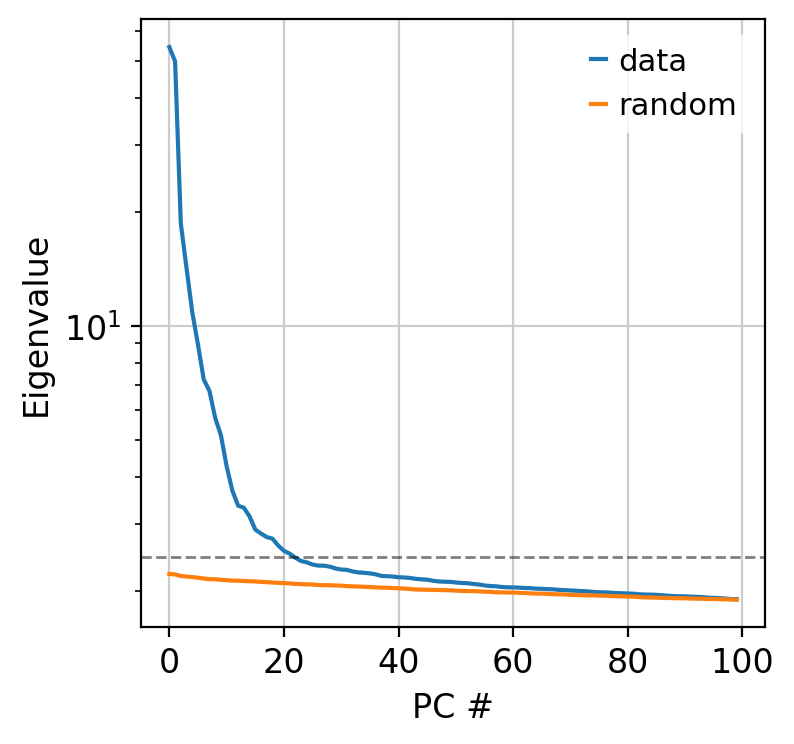

Counting the # of PCs with eigenvalues above random in >95% of trials
Eigenvalue Threshold = 2.45
# Significant PCs = 22


AnnData object with n_obs × n_vars = 8636 × 31859
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'n_genes', 'total_counts', 'sample_prep', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'n_sig_PCs'
    layers: 'raw_nolog', 'raw', 'tpm_nolog', 'tpm'

In [ ]:
get_significant_pcs(adata, n_iter = 10, n_comps_test = 100, threshold_method='95', show_plots=True)

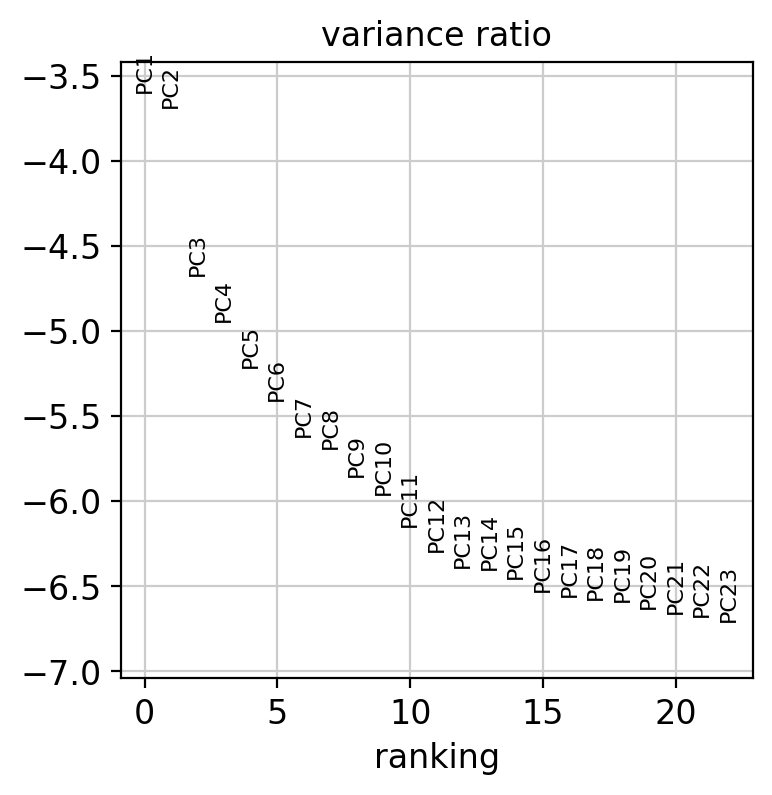

In [ ]:
#Principal Component Analysis

sc.tl.pca(adata, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata, log=True, n_pcs=22) # scanpy generates the filename automatically

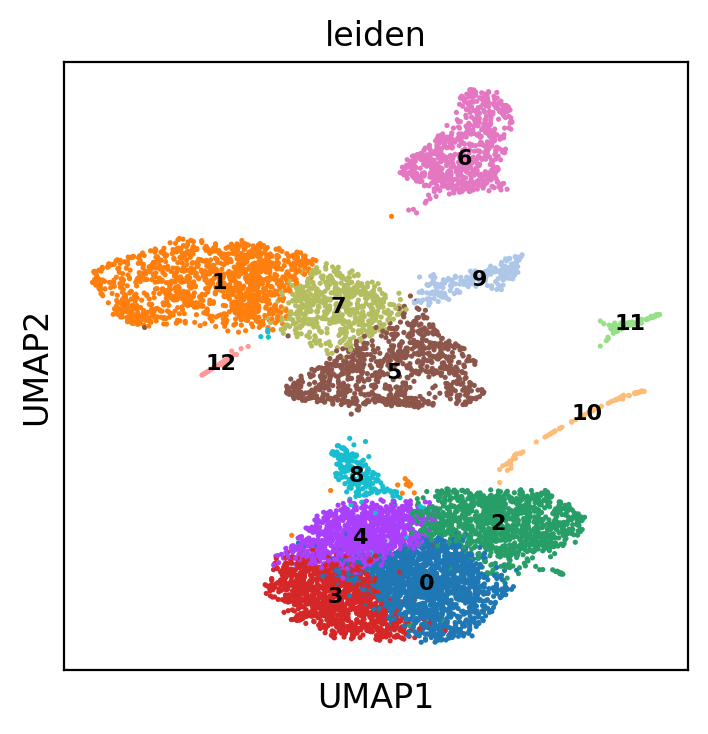

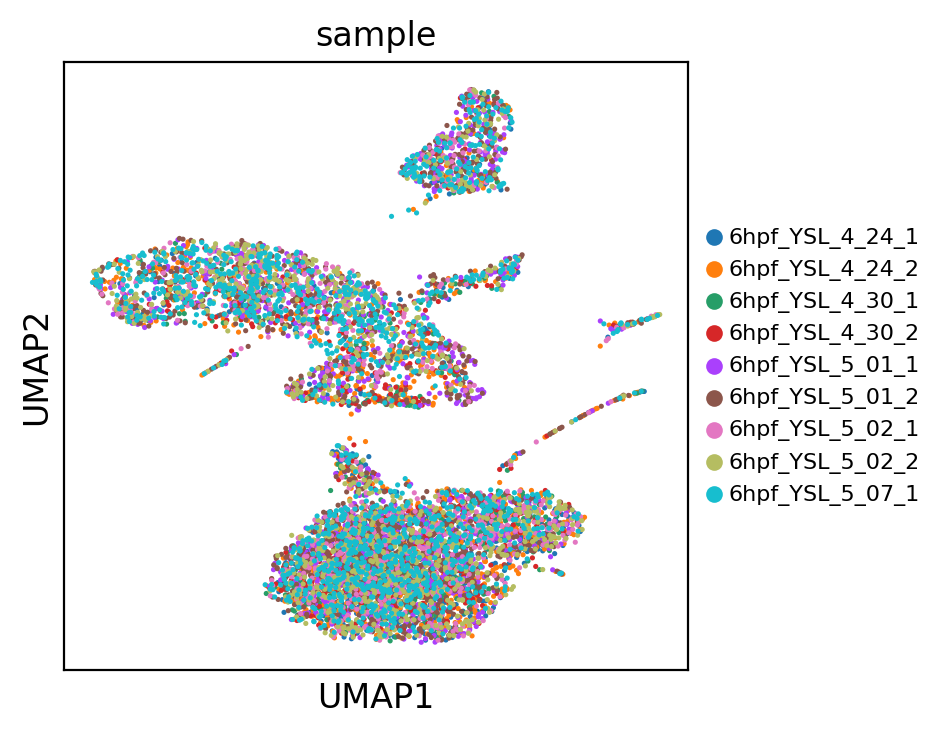

In [ ]:
#UMAP and Leiden Clustering

sc.pp.neighbors(adata, n_neighbors=10, n_pcs=22)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.6)
sc.pl.umap(adata, color=['leiden'], legend_fontsize=8, legend_loc='on data')
sc.pl.umap(adata, color=['sample'], legend_fontsize=8)

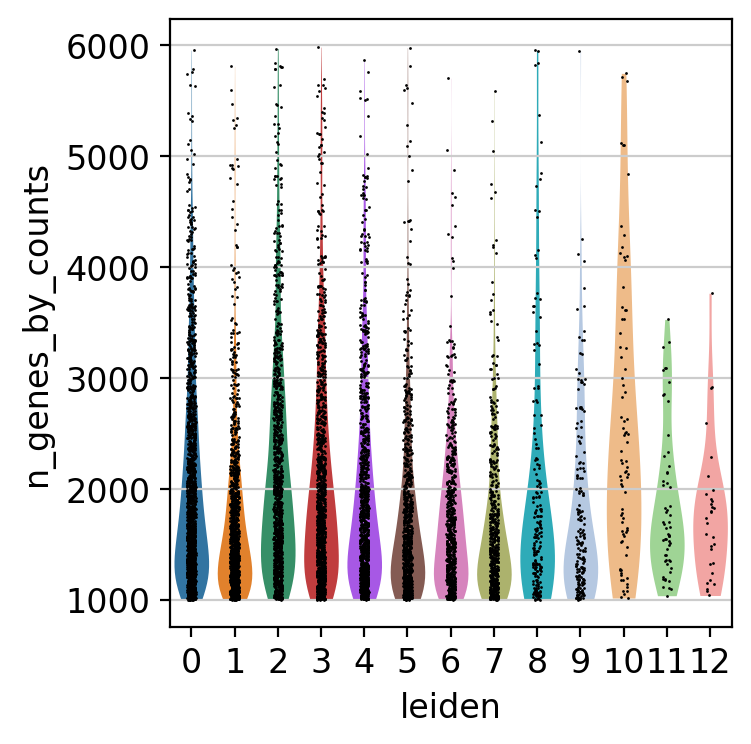

In [ ]:
sc.pl.violin(adata,keys='n_genes_by_counts',groupby='leiden')

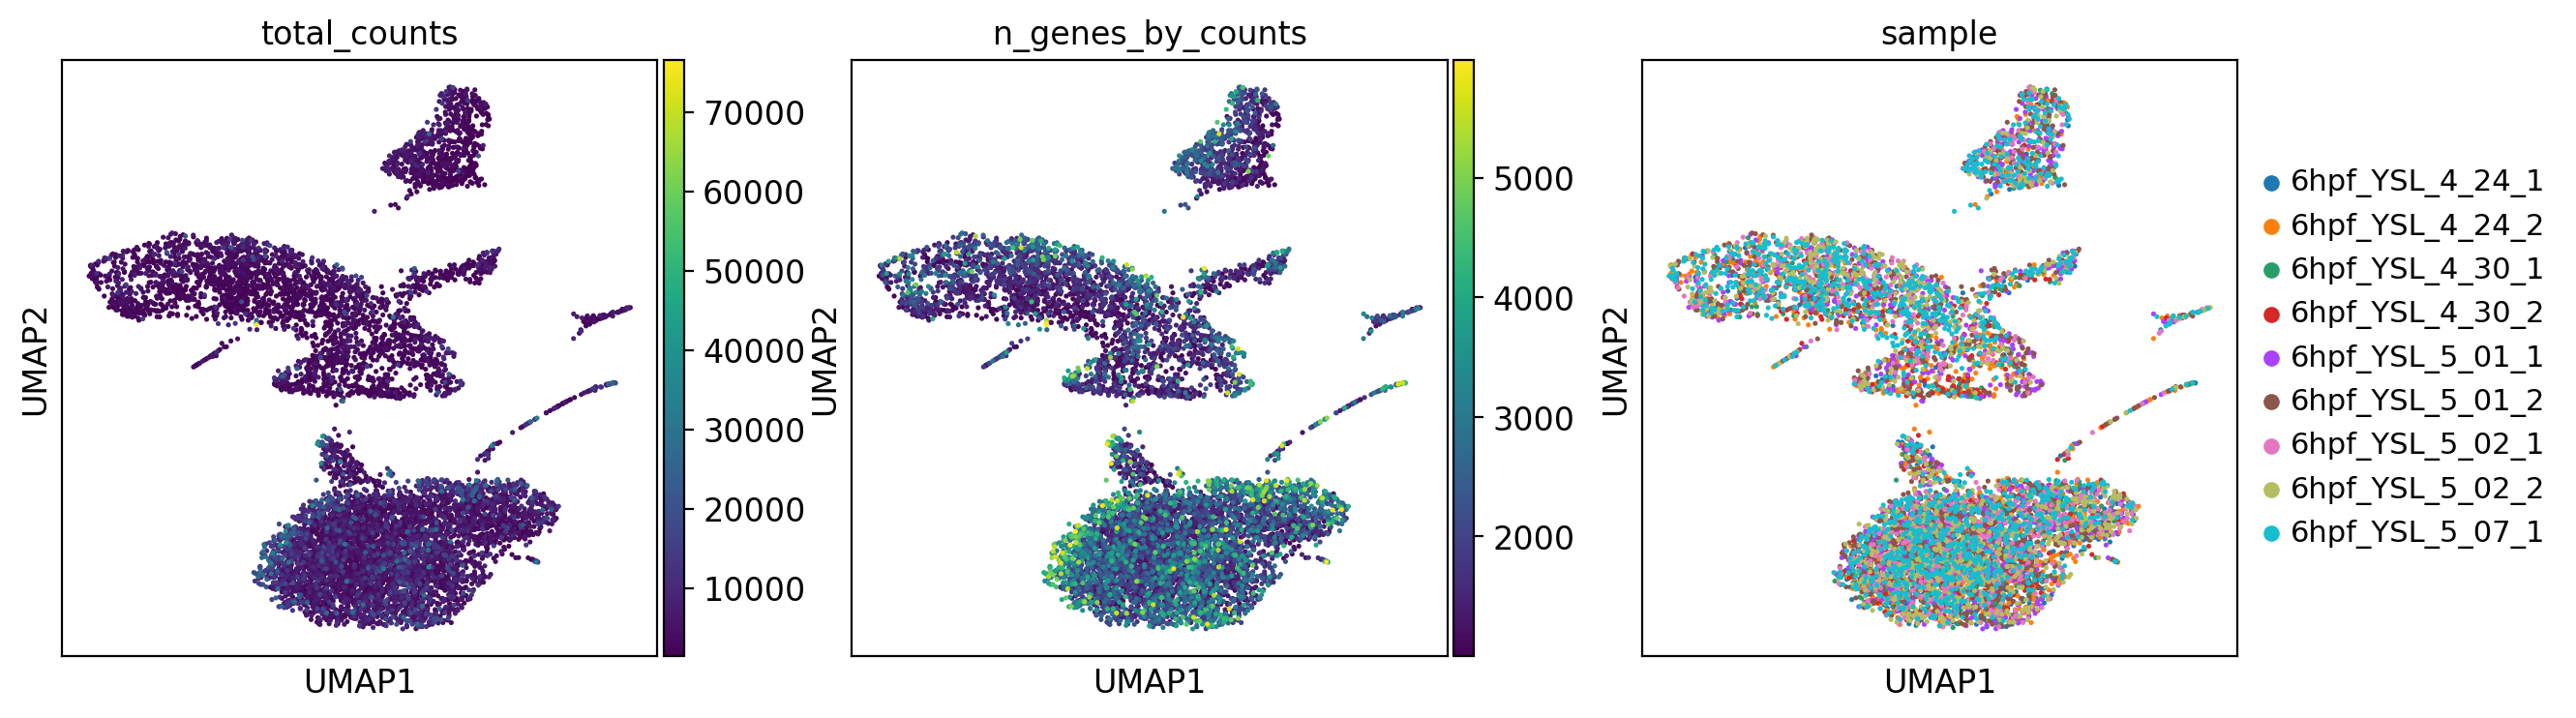

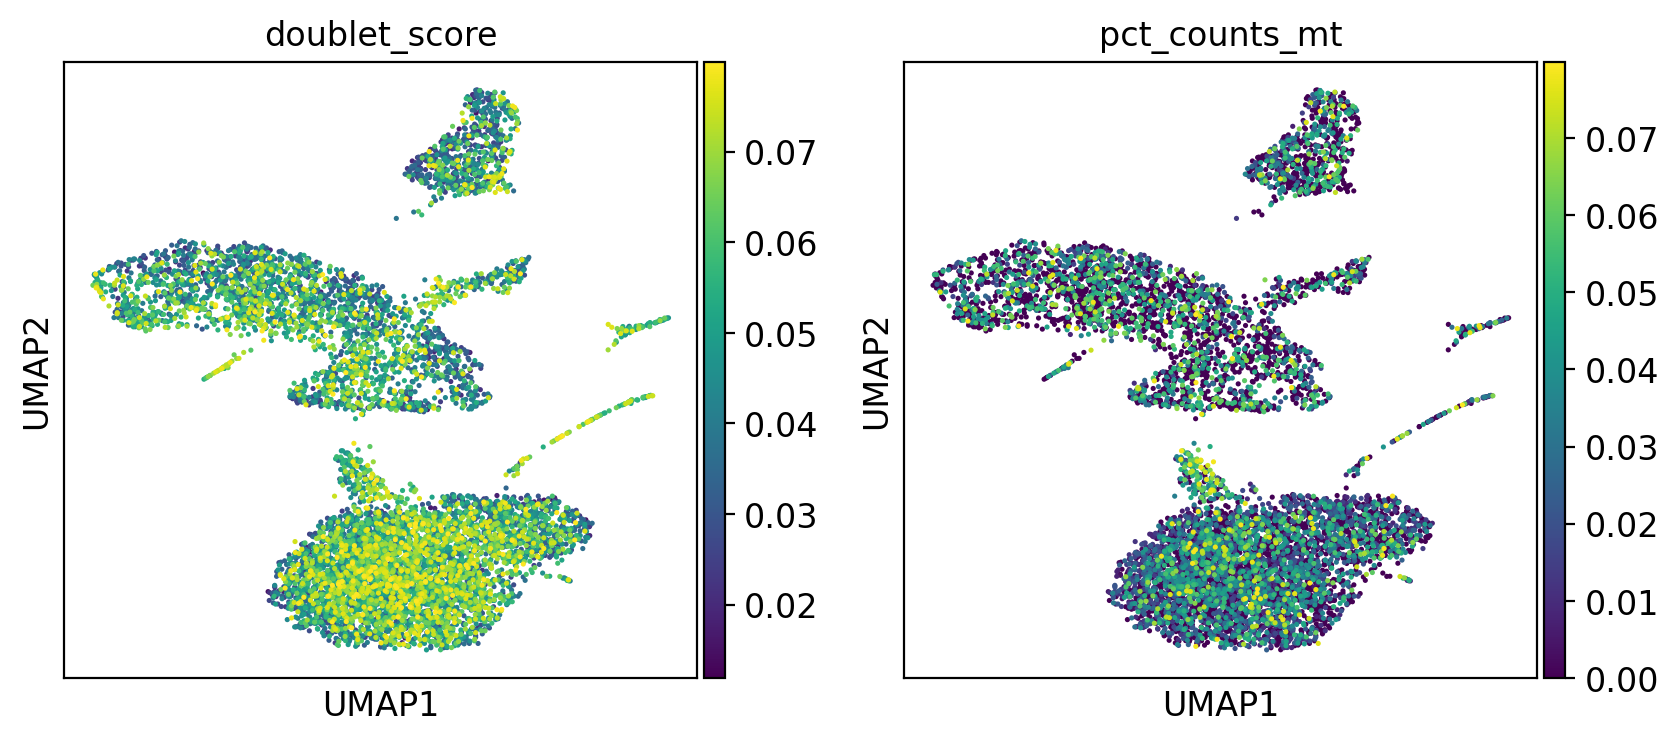

In [ ]:
sc.pl.umap(adata, color=['total_counts','n_genes_by_counts','sample'], layer='raw')
sc.pl.umap(adata, color=['doublet_score','pct_counts_mt'], layer='raw')

# Save h5ad

In [ ]:
adata.write(save_path + 'YSL-full_pp_norm.h5ad')